# Quantum Feature Maps: Classical Data Encoding in Hilbert Space
## Based on Schuld & Killoran, *Quantum machine learning in feature Hilbert spaces* (2018)

This notebook implements the four quantum feature maps introduced in the paper. For each map we:
1. Define the encoding function mathematically
2. Implement a Python function that takes the 10 classical data points as input
3. Return and visualise the encoded quantum states
4. Compute and visualise the induced kernel matrix $K_{ij} = \kappa(\mathbf{x}^{(i)}, \mathbf{x}^{(j)})$


## Setup: Imports & Configuration

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 12})
print('Libraries loaded successfully.')


Libraries loaded successfully.


## Classical Data Points

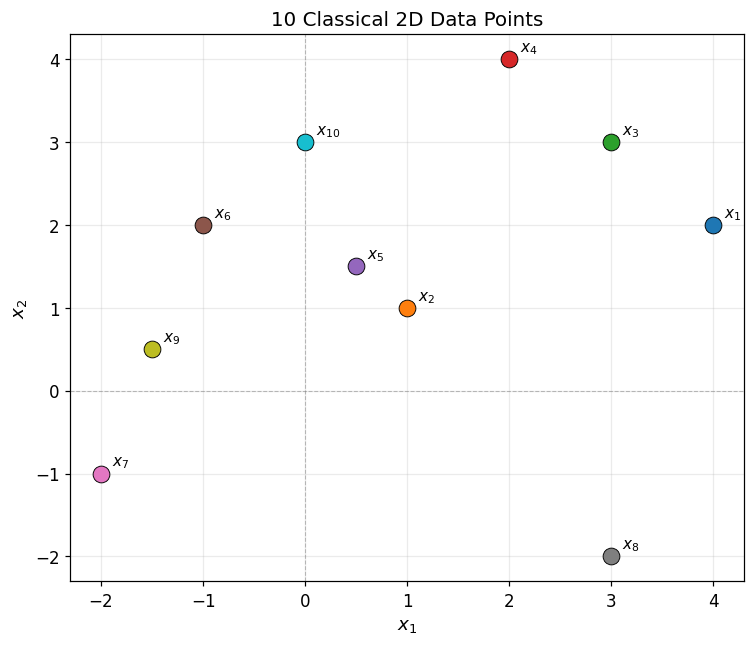

Data points:
  x^( 1) = (  4.0,   2.0)
  x^( 2) = (  1.0,   1.0)
  x^( 3) = (  3.0,   3.0)
  x^( 4) = (  2.0,   4.0)
  x^( 5) = (  0.5,   1.5)
  x^( 6) = ( -1.0,   2.0)
  x^( 7) = ( -2.0,  -1.0)
  x^( 8) = (  3.0,  -2.0)
  x^( 9) = ( -1.5,   0.5)
  x^(10) = (  0.0,   3.0)


In [4]:
# 10 classical 2D data points  x = (x1, x2)
data_points = np.array([
    [ 4.0,  2.0],   # x1
    [ 1.0,  1.0],   # x2
    [ 3.0,  3.0],   # x3
    [ 2.0,  4.0],   # x4
    [ 0.5,  1.5],   # x5
    [-1.0,  2.0],   # x6
    [-2.0, -1.0],   # x7
    [ 3.0, -2.0],   # x8
    [-1.5,  0.5],   # x9
    [ 0.0,  3.0],   # x10
])
N_pts = len(data_points) # number of points
labels = [f'$x_{{{i+1}}}$' for i in range(N_pts)] # data labels for plotting

fig, ax = plt.subplots(figsize=(7, 6)) # create figure/plot area
colors = [plt.cm.tab10(i / N_pts) for i in range(N_pts)] # colormap
for i, (pt, lbl) in enumerate(zip(data_points, labels)): 
    ax.scatter(*pt, color=colors[i], s=120, zorder=5, edgecolors='k', linewidths=0.6) # star is an unpacking operator, just learned about this
    # *pt, if pt=(1,2,), then instead of calling pt[0] and pt[1], *pt is a pythonic operator to do it succinctly
    ax.annotate(lbl, pt, textcoords='offset points', xytext=(7, 5), fontsize=10) # xytext is a text alignment function
ax.axhline(0, color='gray', lw=0.7, ls='--', alpha=0.5) # plot x-axis
ax.axvline(0, color='gray', lw=0.7, ls='--', alpha=0.5) # plot y-axis
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$') # axis labels
ax.set_title('10 Classical 2D Data Points') 
ax.grid(True, alpha=0.25) # plot grid
plt.tight_layout(); plt.show() 

print('Data points:')
for i, pt in enumerate(data_points):
    print(f'  x^({i+1:2d}) = ({pt[0]:5.1f}, {pt[1]:5.1f})')


---
## 1. Basis Encoding

**Definition.** For binary input $\mathbf{x} \in \{0,1\}^n$, the computational basis state is:
$$U_\phi : \mathbf{x} \in \{0,1\}^n \;\longrightarrow\; |i\rangle$$
where $i$ is the integer (decimal) representation of the bit-string $\mathbf{x}$.

**Hilbert space:** $\mathcal{F} = \mathbb{C}^{2^n}$ (dimension $2^n$).

**Feature vector:** $|\phi(\mathbf{x})\rangle = |i\rangle$ — a standard basis vector (one-hot).

**Induced kernel:**
$$\kappa(\mathbf{x}, \mathbf{x}') = \langle i | j \rangle = \delta_{ij}$$
A binary similarity measure — equals 1 if inputs share the same quantised encoding, 0 otherwise.

**Encoding real-valued data:** For real inputs we first *quantise* each feature $x_k$ into an $n_{\text{bits}}$-bit integer:
$$x_k \;\mapsto\; b_k = \operatorname{round}\!\left(\frac{x_k - x_{\min}}{x_{\max} - x_{\min}} \cdot (2^{n_{\text{bits}}} - 1)\right)$$
then concatenate the bit-strings of all $N$ features to form a single $n = N \cdot n_{\text{bits}}$ qubit register.


In [7]:
def basis_encoding(x, n_bits=4, x_min=-5.0, x_max=5.0):
    """
    Basis encoding for real-valued input x in R^N.

    Each feature is quantised to n_bits bits, then all bit-strings are
    concatenated to form the index i of the computational basis state |i>.

    Parameters
    ----------
    x      : vector of data (classical)
    n_bits : int  -- bits per feature
    x_min, x_max : float  -- clipping range for quantisation

    Returns
    -------
    state       : ndarray (2^(N*n_bits),)  -- one-hot basis-state vector
    bit_strings : list of str              -- binary string per feature
    full_binary : str                      -- concatenated bit-string
    full_index  : int                      -- integer index i of |i>
    """
    x = np.asarray(x, dtype=float) # convert to array
    x_clipped = np.clip(x, x_min, x_max) # clipping is an issue
    # clipping involves capping the allowable range of values of the features being ingested in the encoding 
    # it is not clear to me how we clip without loss of information
    # clipping has to be informed by the data itself.. 
    # a function is needed to determine clip values (percentiles, perhaps?)
    x_scaled  = (x_clipped - x_min) / (x_max - x_min) * (2**n_bits - 1) # scale input data to [0,15] for 4 bit binary representation
    x_int     = np.round(x_scaled).astype(int) # round to nearest whole number
    bit_strings  = [format(xi, f'0{n_bits}b') for xi in x_int] # list comprehension, holds binary string representations
    full_binary  = ''.join(bit_strings) # concatenates binary strings in bit_strings
    full_index   = int(full_binary, 2) # convert from binary to integer 
    dim          = 2 ** (len(x) * n_bits) # Hilbert space dimensions 
    state        = np.zeros(dim) # instatntiate 0 vector
    state[full_index] = 1.0 # place a 1 in the space corresponding to the integer representation of the binary encoding
    return state, bit_strings, full_binary, full_index
# if the binary encoding yields 143 (when converted to an integer), then put a 1 in the 143rd spot of the 2^n length vector of zeros... 
# this is the basis state encoding... each classical date point gets encoded as binary strings, then converted to an integer, and 
# [00000...0010000....1000.....0001000000....00] is the outcome.

def basis_kernel(x, x_prime, n_bits=4):
    """
    Kernel from basis encoding: kappa(x, x') = delta_{i,j}.
    Returns 1 if both points map to the same basis state, else 0.
    """
    _, _, _, i = basis_encoding(x, n_bits=n_bits)
    _, _, _, j = basis_encoding(x_prime, n_bits=n_bits)
    return float(i == j)


# Encode all 10 data points
n_bits = 4
print(f'Basis encoding  (n_bits={n_bits} per feature, total {2*n_bits} qubits)')
print(f'Hilbert-space dimension: 2^{2*n_bits} = {2**(2*n_bits)}')
print(f"\n{'Point':<10} {'x1':>6} {'x2':>6}  {'bits x1':<10} {'bits x2':<10}  {'full bitstring':<14} {'index |i>'}")
print('-'*75)
encoded_basis = []
for i, pt in enumerate(data_points):
    state, bits, full_bin, idx = basis_encoding(pt, n_bits=n_bits)
    encoded_basis.append({'state': state, 'bits': bits, 'full_bin': full_bin, 'index': idx})
    print(f'x^({i+1:2d})   {pt[0]:6.1f} {pt[1]:6.1f}  {bits[0]:<10} {bits[1]:<10}  {full_bin:<14} {idx}')


Basis encoding  (n_bits=4 per feature, total 8 qubits)
Hilbert-space dimension: 2^8 = 256

Point          x1     x2  bits x1    bits x2     full bitstring index |i>
---------------------------------------------------------------------------
x^( 1)      4.0    2.0  1110       1010        11101010       234
x^( 2)      1.0    1.0  1001       1001        10011001       153
x^( 3)      3.0    3.0  1100       1100        11001100       204
x^( 4)      2.0    4.0  1010       1110        10101110       174
x^( 5)      0.5    1.5  1000       1010        10001010       138
x^( 6)     -1.0    2.0  0110       1010        01101010       106
x^( 7)     -2.0   -1.0  0100       0110        01000110       70
x^( 8)      3.0   -2.0  1100       0100        11000100       196
x^( 9)     -1.5    0.5  0101       1000        01011000       88
x^(10)      0.0    3.0  1000       1100        10001100       140


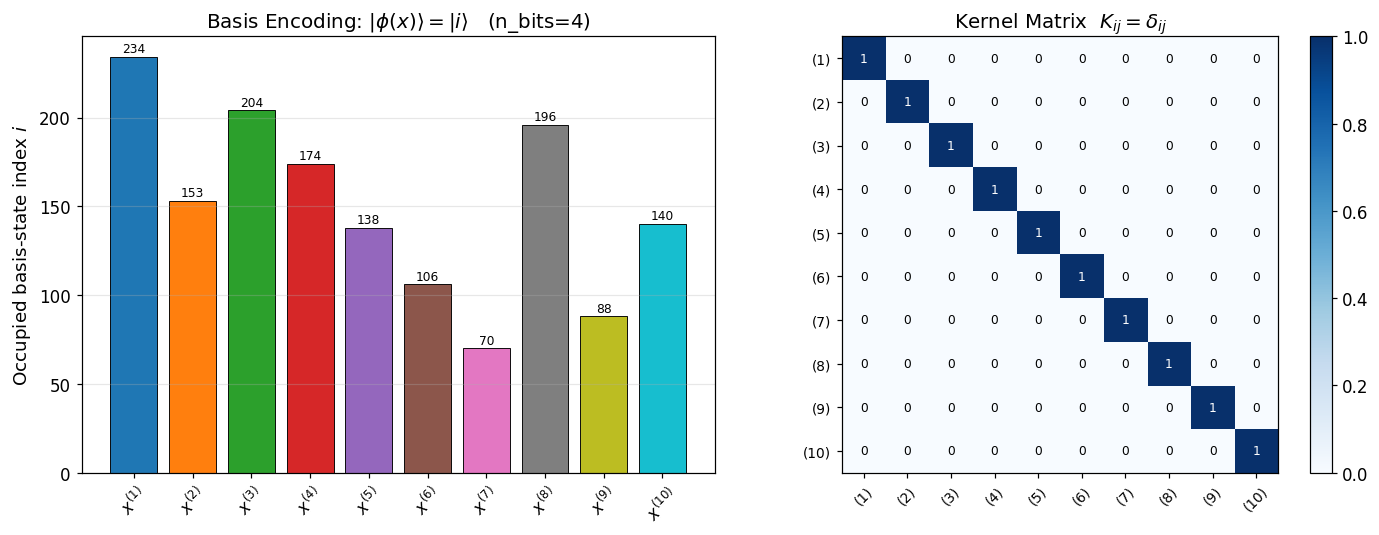

Diagonal = 1 (self-similarity). Off-diagonal = 1 only if two points quantise to the same binary string.


In [17]:
# Visualisation: Basis Encoding
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: occupied basis-state indices
ax = axes[0]
indices = [e['index'] for e in encoded_basis]
bars = ax.bar(range(N_pts), indices, color=colors, edgecolor='k', linewidth=0.6)
ax.set_xticks(range(N_pts))
ax.set_xticklabels([f'$x^{{({i+1})}}$' for i in range(N_pts)], rotation=45)
ax.set_ylabel('Occupied basis-state index $i$')
ax.set_title(f'Basis Encoding: $|\\phi(x)\\rangle = |i\\rangle$   (n_bits={n_bits})')
ax.grid(True, axis='y', alpha=0.3)
for bar, idx in zip(bars, indices):
    ax.text(bar.get_x() + bar.get_width()/2, idx + 1, str(idx), ha='center', va='bottom', fontsize=8)

# Right: kernel matrix
ax2 = axes[1]
K_basis = np.array([[basis_kernel(data_points[i], data_points[j], n_bits=n_bits)
                     for j in range(N_pts)] for i in range(N_pts)])
im = ax2.imshow(K_basis, cmap='Blues', vmin=0, vmax=1)
ax2.set_xticks(range(N_pts)); ax2.set_yticks(range(N_pts))
ax2.set_xticklabels([f'({i+1})' for i in range(N_pts)], rotation=45, fontsize=9)
ax2.set_yticklabels([f'({i+1})' for i in range(N_pts)], fontsize=9)
plt.colorbar(im, ax=ax2)
ax2.set_title('Kernel Matrix  $K_{ij} = \\delta_{ij}$')
for r in range(N_pts):
    for c in range(N_pts):
        ax2.text(c, r, f'{K_basis[r,c]:.0f}', ha='center', va='center', fontsize=8,
                 color='white' if K_basis[r,c] > 0.5 else 'black')
plt.tight_layout(); plt.show()
print('Diagonal = 1 (self-similarity). Off-diagonal = 1 only if two points quantise to the same binary string.')


---
## 2. Amplitude Encoding

**Definition.** A normalised vector $\mathbf{x} \in \mathbb{R}^N$ (with $N = 2^n$) is encoded as the amplitudes of an $n$-qubit state:
$$U_\phi : \mathbf{x} \in \mathbb{R}^N \;\longrightarrow\; |\psi_{\mathbf{x}}\rangle = \sum_{i=0}^{N-1} \frac{x_i}{\|\mathbf{x}\|}\,|i\rangle$$

**Hilbert space:** $\mathcal{F} = \mathbb{C}^N$ — requires $\log_2 N$ qubits.

**Feature vector:** $|\phi(\mathbf{x})\rangle = \hat{\mathbf{x}} = \mathbf{x}/\|\mathbf{x}\|$ — the unit-normalised input.

**Induced kernel (linear / cosine kernel):**
$$\kappa(\mathbf{x}, \mathbf{x}') = \langle\psi_{\mathbf{x}}|\psi_{\mathbf{x}'}\rangle = \frac{\mathbf{x}^\top \mathbf{x}'}{\|\mathbf{x}\|\,\|\mathbf{x}'\|}$$

This is the **cosine similarity** between the two data points.

> **Note for $N=2$:** We need only **1 qubit**: $|\psi_\mathbf{x}\rangle = \frac{x_1}{\|\mathbf{x}\|}|0\rangle + \frac{x_2}{\|\mathbf{x}\|}|1\rangle$, which lies on the real great circle of the Bloch sphere. The magnitude $\|\mathbf{x}\|$ is completely discarded — amplitude encoding is invariant to rescaling.


In [18]:
# ── Amplitude Encoding ───────────────────────────────────────────────────────

def amplitude_encoding(x):
    """
    Amplitude encoding: x in R^N  ->  |psi_x> = x / ||x||  (normalised state vector).

    Parameters
    ----------
    x : array-like, shape (N,)

    Returns
    -------
    state : ndarray, shape (N,)  -- unit-normalised quantum state
    norm  : float                -- ||x|| (discarded by encoding)
    """
    x = np.asarray(x, dtype=float)
    norm = np.linalg.norm(x)
    if norm == 0:
        raise ValueError('Cannot amplitude-encode the zero vector.')
    return x / norm, norm


def amplitude_kernel(x, x_prime):
    """
    Kernel from amplitude encoding:
    kappa(x, x') = <psi_x | psi_{x'}> = (x/||x||) . (x'/||x'||)  [cosine similarity]
    """
    phi_x,  _ = amplitude_encoding(x)
    phi_xp, _ = amplitude_encoding(x_prime)
    return float(np.dot(phi_x, phi_xp))


# Encode all 10 data points
encoded_amp = []
print('Amplitude Encoding  --  1 qubit (N=2 features, 2-dim Hilbert space)')
print(f"\n{'Point':<10}  {'x1':>6} {'x2':>6}  {'||x||':>7}  {'alpha=x1/||x||':>16} {'beta=x2/||x||':>16}  {'norm check':>10}")
print('-'*85)
for i, pt in enumerate(data_points):
    state, norm = amplitude_encoding(pt)
    encoded_amp.append({'state': state, 'norm': norm})
    print(f'x^({i+1:2d})   {pt[0]:6.2f} {pt[1]:6.2f}  {norm:7.3f}  {state[0]:16.6f} {state[1]:16.6f}  {np.dot(state,state):10.8f}')


Amplitude Encoding  --  1 qubit (N=2 features, 2-dim Hilbert space)

Point           x1     x2    ||x||    alpha=x1/||x||    beta=x2/||x||  norm check
-------------------------------------------------------------------------------------
x^( 1)     4.00   2.00    4.472          0.894427         0.447214  1.00000000
x^( 2)     1.00   1.00    1.414          0.707107         0.707107  1.00000000
x^( 3)     3.00   3.00    4.243          0.707107         0.707107  1.00000000
x^( 4)     2.00   4.00    4.472          0.447214         0.894427  1.00000000
x^( 5)     0.50   1.50    1.581          0.316228         0.948683  1.00000000
x^( 6)    -1.00   2.00    2.236         -0.447214         0.894427  1.00000000
x^( 7)    -2.00  -1.00    2.236         -0.894427        -0.447214  1.00000000
x^( 8)     3.00  -2.00    3.606          0.832050        -0.554700  1.00000000
x^( 9)    -1.50   0.50    1.581         -0.948683         0.316228  1.00000000
x^(10)     0.00   3.00    3.000          0.000000   

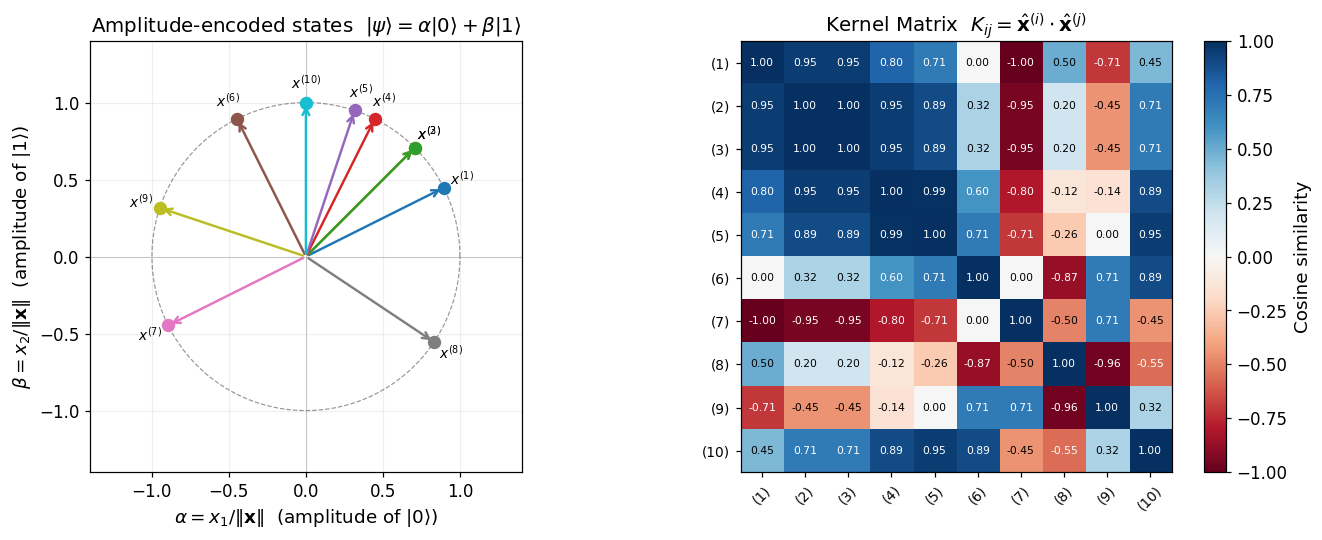

In [19]:
# Visualisation: Amplitude Encoding
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: unit-circle view (1-qubit states are real => lie on a circle)
ax = axes[0]
theta_circ = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta_circ), np.sin(theta_circ), 'k--', lw=0.8, alpha=0.4)
ax.axhline(0, color='gray', lw=0.5, alpha=0.5)
ax.axvline(0, color='gray', lw=0.5, alpha=0.5)
for i, enc in enumerate(encoded_amp):
    a, b = enc['state']
    ax.annotate('', xy=(a, b), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=1.6))
    ax.scatter(a, b, color=colors[i], s=60, zorder=5)
    offset = np.array([a, b]) * 1.13
    ax.text(offset[0], offset[1], labels[i], ha='center', va='center', fontsize=9)
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect('equal')
ax.set_xlabel(r'$\alpha = x_1/\|\mathbf{x}\|$  (amplitude of $|0\rangle$)')
ax.set_ylabel(r'$\beta = x_2/\|\mathbf{x}\|$  (amplitude of $|1\rangle$)')
ax.set_title(r'Amplitude-encoded states  $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$')
ax.grid(True, alpha=0.2)

# Right: kernel (cosine similarity) matrix
ax2 = axes[1]
K_amp = np.array([[amplitude_kernel(data_points[i], data_points[j])
                   for j in range(N_pts)] for i in range(N_pts)])
im = ax2.imshow(K_amp, cmap='RdBu', vmin=-1, vmax=1)
ax2.set_xticks(range(N_pts)); ax2.set_yticks(range(N_pts))
ax2.set_xticklabels([f'({i+1})' for i in range(N_pts)], rotation=45, fontsize=9)
ax2.set_yticklabels([f'({i+1})' for i in range(N_pts)], fontsize=9)
plt.colorbar(im, ax=ax2, label='Cosine similarity')
ax2.set_title(r'Kernel Matrix  $K_{ij} = \hat{\mathbf{x}}^{(i)} \cdot \hat{\mathbf{x}}^{(j)}$')
for r in range(N_pts):
    for c in range(N_pts):
        ax2.text(c, r, f'{K_amp[r,c]:.2f}', ha='center', va='center', fontsize=7,
                 color='white' if abs(K_amp[r,c]) > 0.5 else 'black')
plt.tight_layout(); plt.show()


---
## 3. Product Encoding (Angle Encoding)

**Definition.** Each scalar feature $x_i$ is individually encoded into a single qubit:
$$|\phi(x_i)\rangle = \cos(x_i)\,|0\rangle + \sin(x_i)\,|1\rangle$$

For an $N$-dimensional input $\mathbf{x} = (x_1, \ldots, x_N)^\top$, the full encoding is the tensor product:
$$U_\phi : \mathbf{x} \in \mathbb{R}^N \;\longrightarrow\; |\phi(\mathbf{x})\rangle = \bigotimes_{i=1}^{N} \bigl[\cos(x_i)\,|0\rangle + \sin(x_i)\,|1\rangle\bigr]$$

**Hilbert space:** $\mathcal{F} = (\mathbb{C}^2)^{\otimes N}$ — an $N$-qubit register of dimension $2^N$.

**Induced kernel:** Expanding the inner product across the tensor product:
$$\kappa(\mathbf{x}, \mathbf{x}') = \langle\phi(\mathbf{x})|\phi(\mathbf{x}')\rangle = \prod_{i=1}^{N} \bigl[\cos(x_i)\cos(x_i') + \sin(x_i)\sin(x_i')\bigr] = \prod_{i=1}^{N} \cos(x_i - x_i')$$

> **Properties:** This kernel is *stationary* (depends only on $\mathbf{x}-\mathbf{x}'$), *periodic*, and bounded in $[-1, 1]$. It does not require normalisation of the input. For $N=2$ and our data points, the state lives in a 4-dimensional space spanned by $|00\rangle, |01\rangle, |10\rangle, |11\rangle$.


In [20]:
# ── Product (Angle) Encoding ─────────────────────────────────────────────────

def product_encoding(x):
    """
    Product encoding: x in R^N  ->  |phi(x)> = tensor_i (cos(x_i)|0> + sin(x_i)|1>)

    Parameters
    ----------
    x : array-like, shape (N,)

    Returns
    -------
    state         : ndarray, shape (2^N,)     -- tensor-product state vector
    single_qubits : list of ndarray (2,) each -- individual qubit states
    """
    x = np.asarray(x, dtype=float)
    single_qubits = [np.array([np.cos(xi), np.sin(xi)]) for xi in x]
    state = np.array([1.0])
    for q in single_qubits:
        state = np.kron(state, q)
    return state, single_qubits


def product_kernel(x, x_prime):
    """
    Kernel from product encoding (derived analytically):
    kappa(x, x') = prod_i  cos(x_i - x'_i)

    Proof: <phi(x_i)|phi(x'_i)> = cos(x_i)cos(x'_i) + sin(x_i)sin(x'_i) = cos(x_i - x'_i)
           Full kernel = product over i by tensor-product structure.
    """
    x  = np.asarray(x,  dtype=float)
    xp = np.asarray(x_prime, dtype=float)
    return float(np.prod(np.cos(x - xp)))


# Encode all 10 data points
encoded_prod = []
basis_2q = ['|00>', '|01>', '|10>', '|11>']
print('Product (Angle) Encoding  --  N=2 qubits  ->  4-dim Hilbert space')
print(f"{'Point':<10}  {'|00>':>9} {'|01>':>9} {'|10>':>9} {'|11>':>9}   {'||phi||^2':>10}")
print('-'*70)
for i, pt in enumerate(data_points):
    state, qubits = product_encoding(pt)
    encoded_prod.append({'state': state, 'qubits': qubits})
    print(f'x^({i+1:2d})   {state[0]:9.4f} {state[1]:9.4f} {state[2]:9.4f} {state[3]:9.4f}   {np.dot(state,state):10.8f}')


Product (Angle) Encoding  --  N=2 qubits  ->  4-dim Hilbert space
Point            |00>      |01>      |10>      |11>    ||phi||^2
----------------------------------------------------------------------
x^( 1)      0.2720   -0.5944    0.3149   -0.6882   1.00000000
x^( 2)      0.2919    0.4546    0.4546    0.7081   1.00000000
x^( 3)      0.9801   -0.1397   -0.1397    0.0199   1.00000000
x^( 4)      0.2720    0.3149   -0.5944   -0.6882   1.00000000
x^( 5)      0.0621    0.8754    0.0339    0.4782   1.00000000
x^( 6)     -0.2248    0.4913    0.3502   -0.7651   1.00000000
x^( 7)     -0.2248    0.3502   -0.4913    0.7651   1.00000000
x^( 8)      0.4120    0.9002   -0.0587   -0.1283   1.00000000
x^( 9)      0.0621    0.0339   -0.8754   -0.4782   1.00000000
x^(10)     -0.9900    0.1411   -0.0000    0.0000   1.00000000


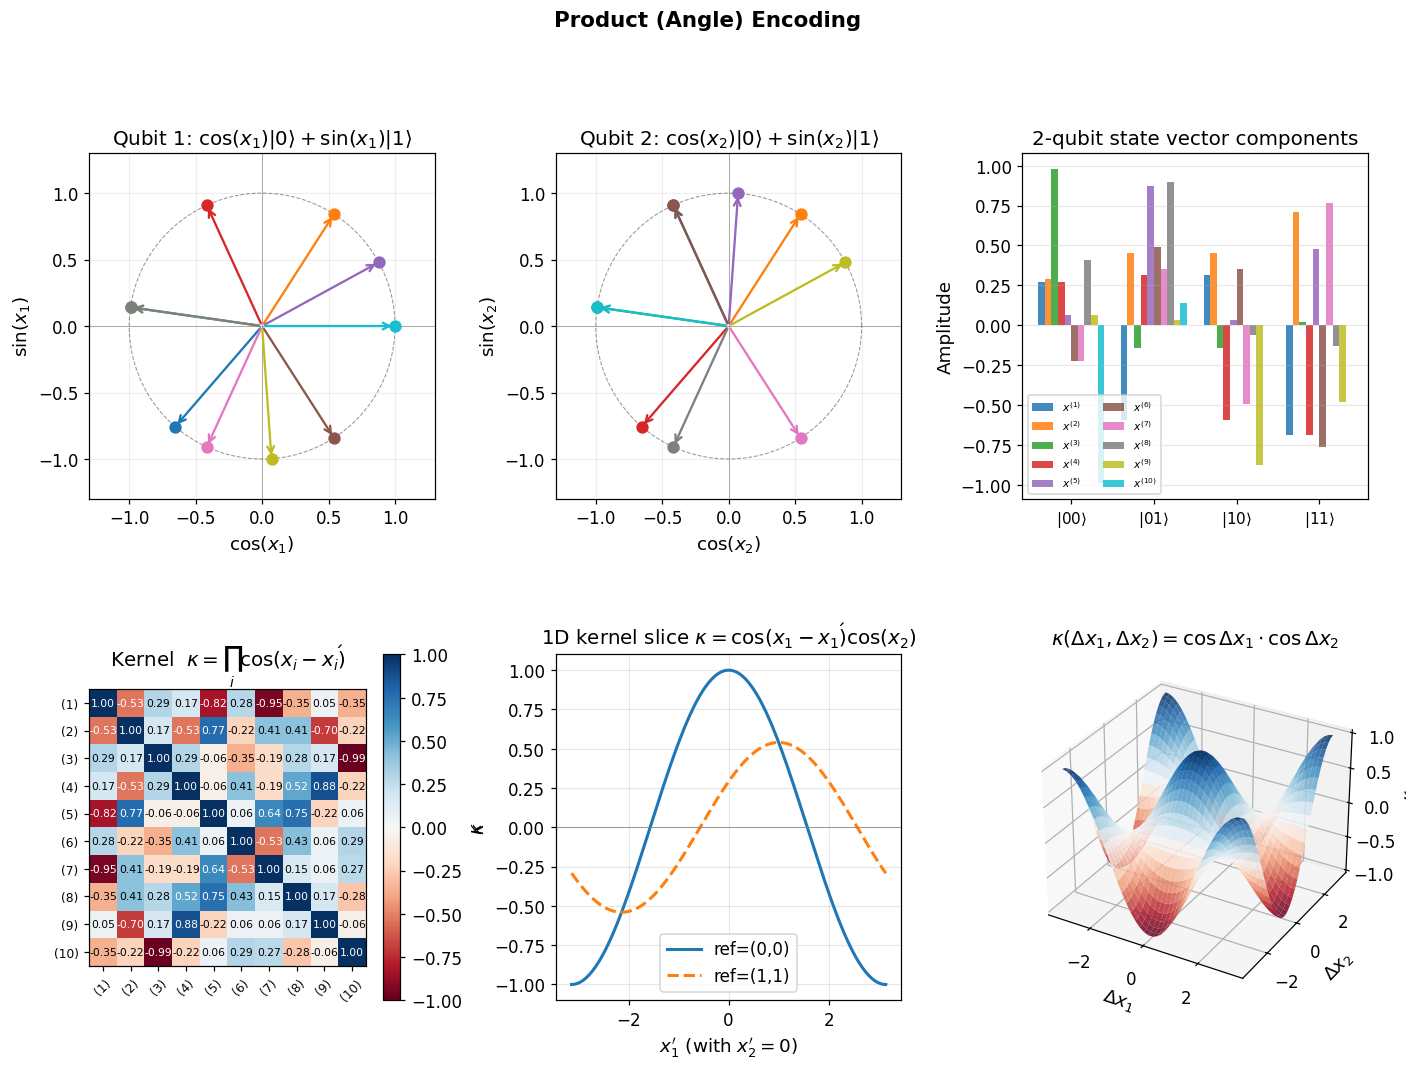

In [21]:
# Visualisation: Product Encoding
fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)
theta_circ = np.linspace(0, 2*np.pi, 300)

# Angle wheel: qubit 1 (x1 feature)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(np.cos(theta_circ), np.sin(theta_circ), 'k--', lw=0.7, alpha=0.4)
ax1.axhline(0, color='gray', lw=0.4); ax1.axvline(0, color='gray', lw=0.4)
for i, enc in enumerate(encoded_prod):
    c1, s1 = enc['qubits'][0]
    ax1.annotate('', xy=(c1, s1), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=1.5))
    ax1.scatter(c1, s1, color=colors[i], s=50, zorder=5)
ax1.set_xlim(-1.3, 1.3); ax1.set_ylim(-1.3, 1.3); ax1.set_aspect('equal')
ax1.set_xlabel(r'$\cos(x_1)$'); ax1.set_ylabel(r'$\sin(x_1)$')
ax1.set_title(r'Qubit 1: $\cos(x_1)|0\rangle + \sin(x_1)|1\rangle$'); ax1.grid(True, alpha=0.2)

# Angle wheel: qubit 2 (x2 feature)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(np.cos(theta_circ), np.sin(theta_circ), 'k--', lw=0.7, alpha=0.4)
ax2.axhline(0, color='gray', lw=0.4); ax2.axvline(0, color='gray', lw=0.4)
for i, enc in enumerate(encoded_prod):
    c2, s2 = enc['qubits'][1]
    ax2.annotate('', xy=(c2, s2), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=1.5))
    ax2.scatter(c2, s2, color=colors[i], s=50, zorder=5)
ax2.set_xlim(-1.3, 1.3); ax2.set_ylim(-1.3, 1.3); ax2.set_aspect('equal')
ax2.set_xlabel(r'$\cos(x_2)$'); ax2.set_ylabel(r'$\sin(x_2)$')
ax2.set_title(r'Qubit 2: $\cos(x_2)|0\rangle + \sin(x_2)|1\rangle$'); ax2.grid(True, alpha=0.2)

# 4-component state vectors as grouped bar chart
ax3 = fig.add_subplot(gs[0, 2])
x_pos = np.arange(4)
width = 0.08
for i, enc in enumerate(encoded_prod):
    ax3.bar(x_pos + i * width, enc['state'], width=width,
            color=colors[i], label=f'$x^{{({i+1})}}$', alpha=0.85)
ax3.set_xticks(x_pos + width * (N_pts - 1) / 2)
ax3.set_xticklabels(['$|00\\rangle$','$|01\\rangle$','$|10\\rangle$','$|11\\rangle$'], fontsize=10)
ax3.set_ylabel('Amplitude'); ax3.set_title(r'2-qubit state vector components')
ax3.legend(fontsize=7, ncol=2); ax3.grid(True, axis='y', alpha=0.3)

# Kernel matrix
ax4 = fig.add_subplot(gs[1, 0])
K_prod = np.array([[product_kernel(data_points[i], data_points[j])
                    for j in range(N_pts)] for i in range(N_pts)])
im = ax4.imshow(K_prod, cmap='RdBu', vmin=-1, vmax=1)
ax4.set_xticks(range(N_pts)); ax4.set_yticks(range(N_pts))
ax4.set_xticklabels([f'({i+1})' for i in range(N_pts)], rotation=45, fontsize=8)
ax4.set_yticklabels([f'({i+1})' for i in range(N_pts)], fontsize=8)
plt.colorbar(im, ax=ax4, label=r'$\kappa$')
ax4.set_title(r'Kernel  $\kappa = \prod_i \cos(x_i - x_i\')$')
for r in range(N_pts):
    for c in range(N_pts):
        ax4.text(c, r, f'{K_prod[r,c]:.2f}', ha='center', va='center', fontsize=7,
                 color='white' if abs(K_prod[r,c]) > 0.5 else 'black')

# 1D kernel slice
ax5 = fig.add_subplot(gs[1, 1])
x_range = np.linspace(-np.pi, np.pi, 200)
for ref_pt, ls, lbl in [([0,0], '-', 'ref=(0,0)'), ([1,1], '--', 'ref=(1,1)')]:
    k_vals = [product_kernel(ref_pt, [v, 0.0]) for v in x_range]
    ax5.plot(x_range, k_vals, ls, lw=2, label=lbl)
ax5.axhline(0, color='gray', lw=0.5)
ax5.set_xlabel(r"$x_1'$ (with $x_2'=0$)")
ax5.set_ylabel(r'$\kappa$'); ax5.set_title(r'1D kernel slice $\kappa = \cos(x_1 - x_1\')\cos(x_2)$')
ax5.legend(); ax5.grid(True, alpha=0.3)

# 2D kernel surface
ax6 = fig.add_subplot(gs[1, 2], projection='3d')
g = np.linspace(-np.pi, np.pi, 40)
G1, G2 = np.meshgrid(g, g)
K_surf = np.cos(G1) * np.cos(G2)
ax6.plot_surface(G1, G2, K_surf, cmap='RdBu', alpha=0.85, linewidth=0)
ax6.set_xlabel(r'$\Delta x_1$'); ax6.set_ylabel(r'$\Delta x_2$'); ax6.set_zlabel(r'$\kappa$')
ax6.set_title(r'$\kappa(\Delta x_1, \Delta x_2) = \cos\Delta x_1 \cdot \cos\Delta x_2$')

fig.suptitle('Product (Angle) Encoding', fontsize=14, fontweight='bold', y=1.01)
plt.show()


---
## 4. Squeezing Feature Map with Phase Encoding

### 4.1 Squeezed Vacuum States in Fock Space

A **squeezed vacuum state** with squeezing strength $r \geq 0$ and phase $\varphi \in \mathbb{R}$ is:
$$|z\rangle \;=\; \frac{1}{\sqrt{\cosh r}} \sum_{n=0}^{\infty} \left(-e^{i\varphi}\tanh r\right)^n \frac{\sqrt{(2n)!}}{2^n\, n!}\,|2n\rangle$$

where $z = r\,e^{i\varphi}$ is the complex squeezing parameter.

> **Key observation:** Only *even* Fock states $|0\rangle, |2\rangle, |4\rangle, \ldots$ are occupied — squeezing creates pairs of photons.

### 4.2 Phase Encoding

Encode a scalar $x_i$ as the **phase** of a squeezed state with fixed squeezing strength $c > 0$ (hyperparameter):
$$U_\phi : x_i \;\longrightarrow\; |(c, x_i)\rangle \;=\; \frac{1}{\sqrt{\cosh c}} \sum_{n=0}^{\infty} \left(-e^{i x_i}\tanh c\right)^n \frac{\sqrt{(2n)!}}{2^n\, n!}\,|2n\rangle$$

For multi-dimensional $\mathbf{x} = (x_1, \ldots, x_N)^\top$:
$$\phi : \mathbf{x} \;\longrightarrow\; |(c, \mathbf{x})\rangle = |(c, x_1)\rangle \otimes \cdots \otimes |(c, x_N)\rangle \;\in\; \mathcal{F}$$

where $\mathcal{F}$ is the $N$-mode Fock space (infinite-dimensional, truncated at cutoff $D$ for computation).

### 4.3 Squeezing Kernel (Equations 7–8 of the paper)

The inner product of two phase-encoded squeezed states has a closed form:
$$\langle (c,x_i) \mid (c, x_i') \rangle = \sqrt{\frac{\operatorname{sech}^2 c}{1 - e^{i(x_i' - x_i)}\tanh^2 c}}$$

The full multi-mode kernel (product over all $N$ modes):
$$\boxed{\kappa(\mathbf{x}, \mathbf{x}'; c) \;=\; \prod_{i=1}^{N} \frac{\operatorname{sech} c}{\sqrt{1 - e^{i(x_i' - x_i)}\tanh^2 c}}}$$

This is complex in general. A real kernel is $|\kappa(\mathbf{x}, \mathbf{x}')|^2$.

**Hyperparameter $c$:** Controls squeezing strength and kernel width. Larger $c$ gives a narrower (more local) kernel.

### 4.4 Linear Separability (Appendix B of the paper)

For distinct data points $x_i \neq x_j$, the encoded states $|(c,x_i)\rangle$ are linearly independent in Fock space. The proof relies on the Vandermonde structure of the Gram matrix: $V_{jn} = \bigl(-e^{i\varphi_j}\tanh c / 2\bigr)^n$, whose determinant is non-zero when all phases are distinct. Consequently, **any dataset becomes linearly separable in Fock space** under the squeezing feature map.


In [22]:
# ── Squeezing Feature Map ─────────────────────────────────────────────────────

def squeezing_state(c, phi, cutoff=60):
    """
    Single-mode squeezed vacuum state in the Fock basis (truncated at `cutoff`).

    Formula:
        |(c, phi)> = 1/sqrt(cosh c) * sum_{n=0}^{inf} (-exp(i*phi)*tanh(c))^n
                     * sqrt((2n)!) / (2^n * n!) * |2n>

    Only EVEN Fock states are populated.

    Parameters
    ----------
    c      : float  -- squeezing strength (hyperparameter, called r in the paper)
    phi    : float  -- squeezing phase (= x_i for the feature map)
    cutoff : int    -- Fock-space truncation

    Returns
    -------
    state : ndarray, shape (cutoff,), complex
    """
    state = np.zeros(cutoff, dtype=complex)
    prefactor = 1.0 / np.sqrt(np.cosh(c))
    tanh_c    = np.tanh(c)
    for n in range(cutoff // 2):
        fock_idx = 2 * n
        if fock_idx >= cutoff:
            break
        coeff  = prefactor
        coeff *= (-np.exp(1j * phi) * tanh_c) ** n
        coeff *= np.sqrt(float(math.factorial(2 * n))) / float(2**n * math.factorial(n))
        state[fock_idx] = coeff
    return state


def squeezing_feature_map(x, c=1.5, cutoff=40):
    """
    Multi-mode squeezing feature map with phase encoding.
    phi(x) = |(c,x)> = |(c,x_1)> tensor |(c,x_2)> tensor ... tensor |(c,x_N)>

    Parameters
    ----------
    x      : array-like, shape (N,)
    c      : float  -- squeezing hyperparameter
    cutoff : int    -- per-mode Fock truncation

    Returns
    -------
    full_state         : ndarray, shape (cutoff^N,), complex  -- tensor-product state
    single_mode_states : list of ndarray  -- individual mode states
    """
    x = np.asarray(x, dtype=float)
    single_mode_states = [squeezing_state(c, xi, cutoff) for xi in x]
    full_state = single_mode_states[0]
    for s in single_mode_states[1:]:
        full_state = np.kron(full_state, s)
    return full_state, single_mode_states


def squeezing_kernel_analytic(x, x_prime, c=1.5):
    """
    Analytic squeezing kernel from Eq. (7)-(8) of Schuld & Killoran (2018):

        kappa(x, x'; c) = prod_i  sech(c) / sqrt(1 - exp(i*(x'_i - x_i)) * tanh^2(c))

    Returns a complex number. Use |kappa|^2 for a real-valued kernel.
    """
    x  = np.asarray(x,  dtype=float)
    xp = np.asarray(x_prime, dtype=float)
    result  = 1.0 + 0j
    sech_c  = 1.0 / np.cosh(c)
    tanh2_c = np.tanh(c) ** 2
    for xi, xpi in zip(x, xp):
        result *= sech_c / np.sqrt(1.0 - np.exp(1j * (xpi - xi)) * tanh2_c)
    return result


def squeezing_kernel_real(x, x_prime, c=1.5):
    """Real kernel: |kappa(x,x';c)|^2"""
    return abs(squeezing_kernel_analytic(x, x_prime, c)) ** 2


# Sanity check: kappa(x, x) == 1 for all x
print('Sanity check: kappa(x, x; c=1.5) = 1 for all data points')
for i, pt in enumerate(data_points):
    k = squeezing_kernel_analytic(pt, pt, c=1.5)
    ok = 'OK' if np.isclose(abs(k), 1.0) else 'FAIL'
    print(f'  x^({i+1:2d}): |kappa| = {abs(k):.8f}  [{ok}]')


Sanity check: kappa(x, x; c=1.5) = 1 for all data points
  x^( 1): |kappa| = 1.00000000  [OK]
  x^( 2): |kappa| = 1.00000000  [OK]
  x^( 3): |kappa| = 1.00000000  [OK]
  x^( 4): |kappa| = 1.00000000  [OK]
  x^( 5): |kappa| = 1.00000000  [OK]
  x^( 6): |kappa| = 1.00000000  [OK]
  x^( 7): |kappa| = 1.00000000  [OK]
  x^( 8): |kappa| = 1.00000000  [OK]
  x^( 9): |kappa| = 1.00000000  [OK]
  x^(10): |kappa| = 1.00000000  [OK]


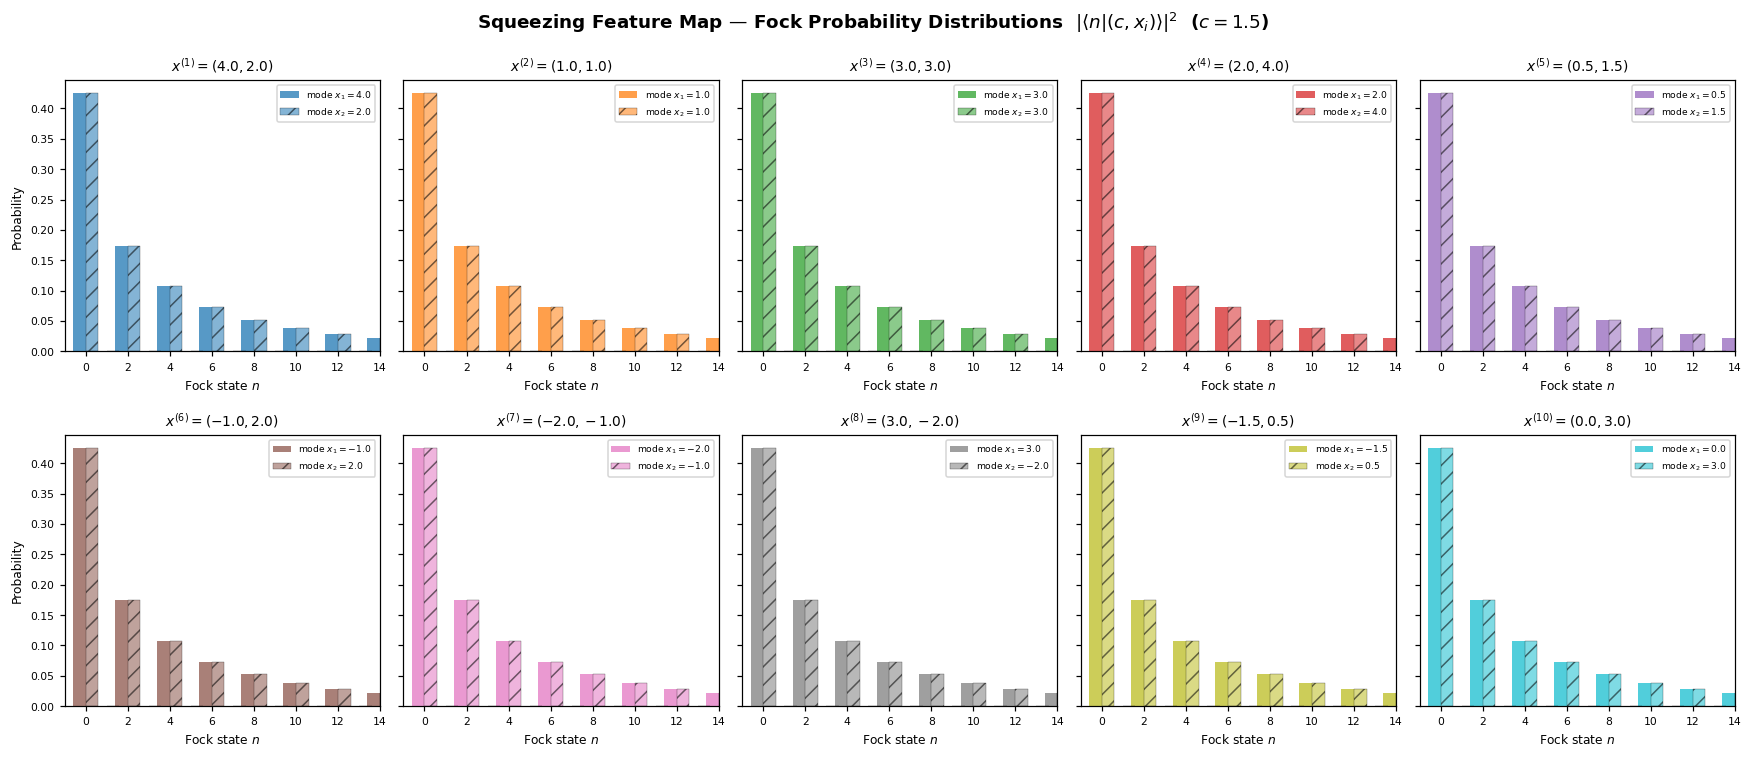

Only even Fock states (n=0,2,4,...) are populated -- squeezing generates photon pairs.


In [23]:
# Visualisation: Single-mode Fock distributions
c_val  = 1.5
cutoff = 40

fig, axes = plt.subplots(2, 5, figsize=(16, 7), sharey=True)
fig.suptitle(
    f'Squeezing Feature Map — Fock Probability Distributions  $|\\langle n|(c,x_i)\\rangle|^2$  ($c={c_val}$)',
    fontsize=12, fontweight='bold')
fock_ns = np.arange(cutoff)
for i, pt in enumerate(data_points):
    ax = axes[i // 5][i % 5]
    _, [s1, s2] = squeezing_feature_map(pt, c=c_val, cutoff=cutoff)
    probs_x1 = np.abs(s1)**2
    probs_x2 = np.abs(s2)**2
    ax.bar(fock_ns - 0.3, probs_x1, width=0.6, alpha=0.75, color=colors[i], label=f'mode $x_1={pt[0]:.1f}$')
    ax.bar(fock_ns + 0.3, probs_x2, width=0.6, alpha=0.55, color=colors[i],
           hatch='//', edgecolor='k', linewidth=0.3, label=f'mode $x_2={pt[1]:.1f}$')
    ax.set_title(f'$x^{{({i+1})}}=({pt[0]:.1f},{pt[1]:.1f})$', fontsize=9)
    ax.set_xlim(-1, 14); ax.set_xlabel('Fock state $n$', fontsize=8)
    if i % 5 == 0:
        ax.set_ylabel('Probability', fontsize=8)
    ax.tick_params(axis='both', labelsize=7)
    ax.legend(fontsize=6, loc='upper right')
plt.tight_layout(); plt.show()
print('Only even Fock states (n=0,2,4,...) are populated -- squeezing generates photon pairs.')


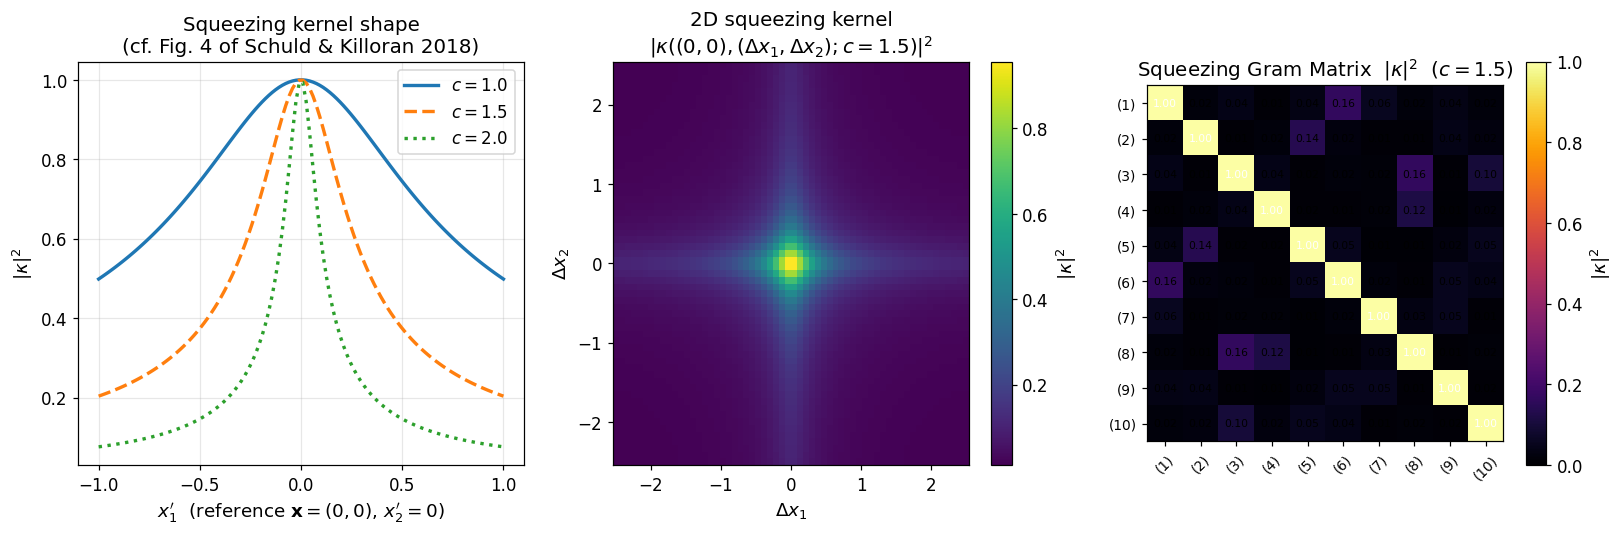

In [24]:
# Visualisation: Squeezing Kernel
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Left: kernel function shape (replicates Fig 4 of paper)
ax = axes[0]
x_range = np.linspace(-1, 1, 120)
x_fixed = np.array([0.0, 0.0])
for c_plot, ls, lbl in [(1.0, '-', '$c=1.0$'), (1.5, '--', '$c=1.5$'), (2.0, ':', '$c=2.0$')]:
    k_line = [abs(squeezing_kernel_analytic(x_fixed, [v, 0.0], c=c_plot))**2 for v in x_range]
    ax.plot(x_range, k_line, ls, lw=2.2, label=lbl)
ax.set_xlabel(r"$x_1'$  (reference $\mathbf{x}=(0,0)$, $x_2'=0$)")
ax.set_ylabel(r'$|\kappa|^2$')
ax.set_title('Squeezing kernel shape\n(cf. Fig. 4 of Schuld & Killoran 2018)')
ax.legend(); ax.grid(True, alpha=0.3)

# Middle: 2D kernel surface
ax2 = axes[1]
delta = np.linspace(-2.5, 2.5, 60)
D1, D2 = np.meshgrid(delta, delta)
K_2d = np.array([[abs(squeezing_kernel_analytic([0.0,0.0], [D1[r,c], D2[r,c]], c=1.5))**2
                  for c in range(len(delta))] for r in range(len(delta))])
im2 = ax2.pcolormesh(D1, D2, K_2d, cmap='viridis', shading='auto')
plt.colorbar(im2, ax=ax2, label=r'$|\kappa|^2$')
ax2.set_xlabel(r'$\Delta x_1$'); ax2.set_ylabel(r'$\Delta x_2$')
ax2.set_title('2D squeezing kernel\n$|\\kappa((0,0),(\\Delta x_1,\\Delta x_2);c=1.5)|^2$')

# Right: Gram matrix for all 10 points
ax3 = axes[2]
K_sq = np.array([[squeezing_kernel_real(data_points[i], data_points[j], c=1.5)
                  for j in range(N_pts)] for i in range(N_pts)])
im3 = ax3.imshow(K_sq, cmap='inferno', vmin=0, vmax=1)
ax3.set_xticks(range(N_pts)); ax3.set_yticks(range(N_pts))
ax3.set_xticklabels([f'({i+1})' for i in range(N_pts)], rotation=45, fontsize=9)
ax3.set_yticklabels([f'({i+1})' for i in range(N_pts)], fontsize=9)
plt.colorbar(im3, ax=ax3, label=r'$|\kappa|^2$')
ax3.set_title(r'Squeezing Gram Matrix  $|\kappa|^2$  ($c=1.5$)')
for r in range(N_pts):
    for c in range(N_pts):
        ax3.text(c, r, f'{K_sq[r,c]:.2f}', ha='center', va='center', fontsize=7,
                 color='white' if K_sq[r,c] > 0.5 else 'black')
plt.tight_layout(); plt.show()


---
## 5. Kernel Comparison Dashboard

| Encoding | Feature space | # qubits/modes | Kernel $\kappa(\mathbf{x}, \mathbf{x}')$ |
|---|---|---|---|
| Basis | $\mathbb{C}^{2^{nN}}$ (discrete) | $N \cdot n_{\text{bits}}$ | $\delta_{ij}$ (Kronecker delta) |
| Amplitude | $\mathbb{C}^N$ | $\log_2 N$ | $\hat{\mathbf{x}} \cdot \hat{\mathbf{x}}'$ (cosine similarity) |
| Product | $(\mathbb{C}^2)^{\otimes N}$ | $N$ | $\prod_i \cos(x_i - x_i')$ |
| Squeezing | Fock space (truncated) | $N$ modes (CV) | $\prod_i \operatorname{sech}(c)/\sqrt{1-e^{i\Delta x_i}\tanh^2 c}$ |


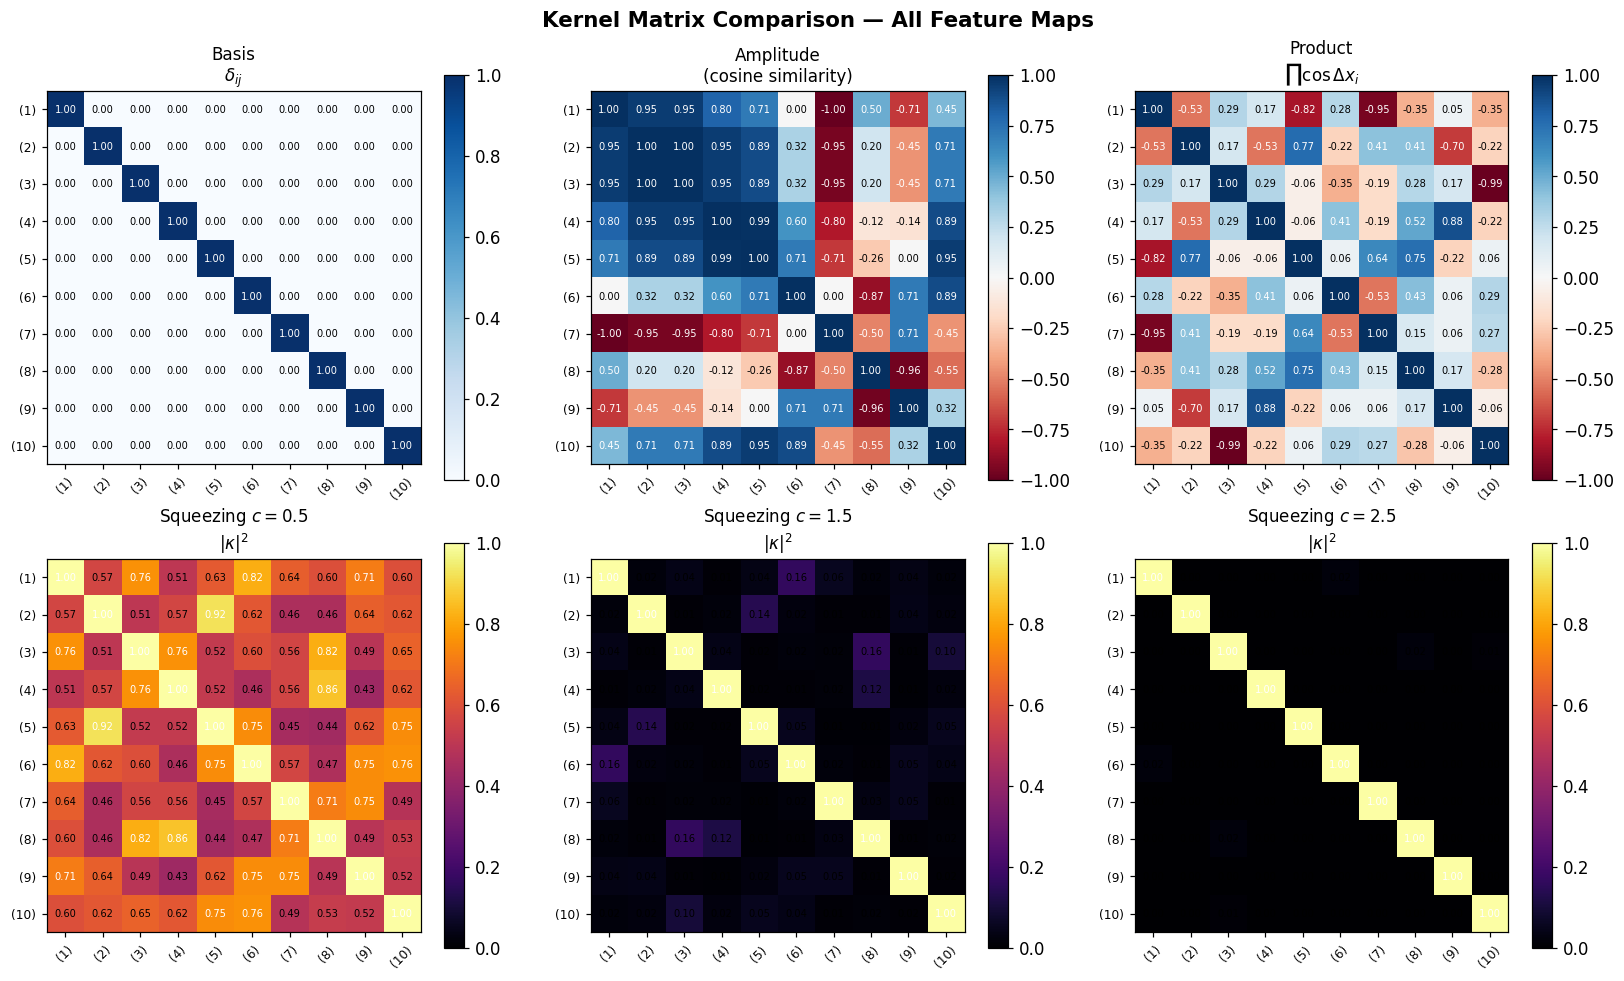

In [25]:
# Kernel Matrix Dashboard
K_sq_05 = np.array([[squeezing_kernel_real(data_points[i], data_points[j], c=0.5)
                     for j in range(N_pts)] for i in range(N_pts)])
K_sq_25 = np.array([[squeezing_kernel_real(data_points[i], data_points[j], c=2.5)
                     for j in range(N_pts)] for i in range(N_pts)])

K_dict = [
    ('Basis\n$\\delta_{ij}$',             K_basis.real, 'Blues',  0, 1),
    ('Amplitude\n(cosine similarity)',    K_amp,        'RdBu',  -1, 1),
    ('Product\n$\\prod\\cos\\Delta x_i$', K_prod,       'RdBu',  -1, 1),
    ('Squeezing $c=0.5$\n$|\\kappa|^2$',  K_sq_05,      'inferno', 0, 1),
    ('Squeezing $c=1.5$\n$|\\kappa|^2$',  K_sq,         'inferno', 0, 1),
    ('Squeezing $c=2.5$\n$|\\kappa|^2$',  K_sq_25,      'inferno', 0, 1),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for ax, (title, K, cmap, vmin, vmax) in zip(axes, K_dict):
    im = ax.imshow(K, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N_pts)); ax.set_yticks(range(N_pts))
    ax.set_xticklabels([f'({i+1})' for i in range(N_pts)], rotation=45, fontsize=8)
    ax.set_yticklabels([f'({i+1})' for i in range(N_pts)], fontsize=8)
    plt.colorbar(im, ax=ax)
    ax.set_title(title, fontsize=11)
    for r in range(N_pts):
        for c in range(N_pts):
            txt_color = 'white' if abs(K[r,c]) > (vmax + vmin) / 2 + (vmax - vmin)*0.2 else 'black'
            ax.text(c, r, f'{K[r,c]:.2f}', ha='center', va='center', fontsize=6.5, color=txt_color)
fig.suptitle('Kernel Matrix Comparison — All Feature Maps', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


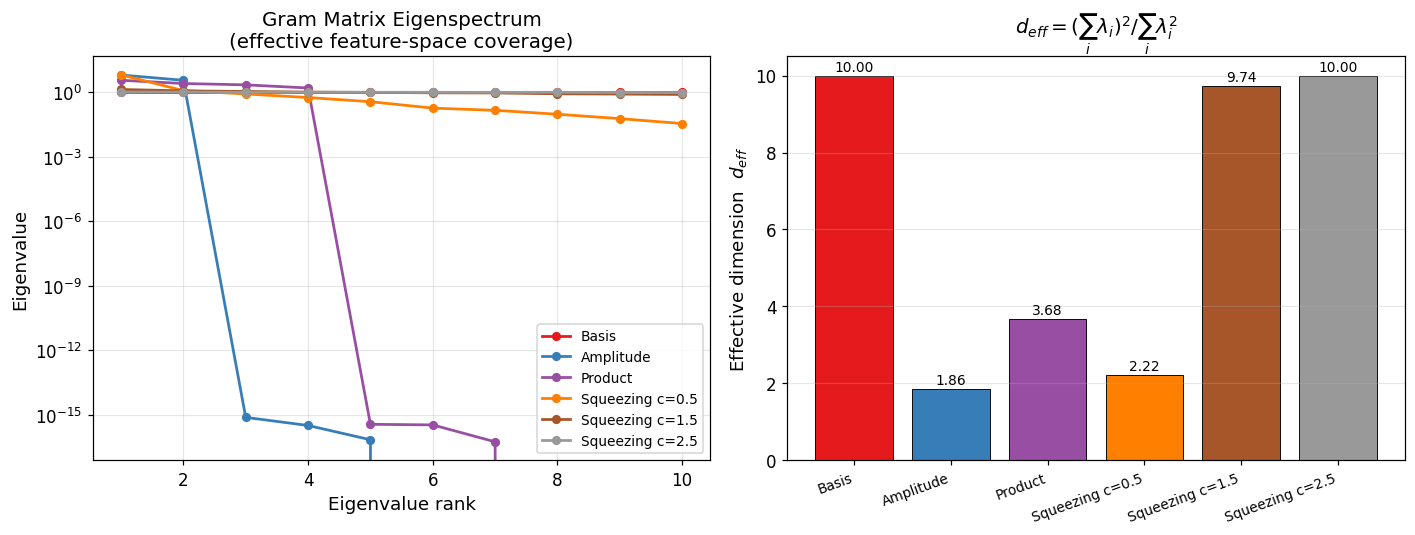

Effective dimensionality (participation ratio):
  Basis                   d_eff = 10.000
  Amplitude               d_eff = 1.860
  Product                 d_eff = 3.679
  Squeezing c=0.5         d_eff = 2.223
  Squeezing c=1.5         d_eff = 9.744
  Squeezing c=2.5         d_eff = 9.998


In [26]:
# Eigenspectrum Comparison
kernel_info = [
    ('Basis',           K_basis.real),
    ('Amplitude',       K_amp),
    ('Product',         K_prod),
    ('Squeezing c=0.5', K_sq_05),
    ('Squeezing c=1.5', K_sq),
    ('Squeezing c=2.5', K_sq_25),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
spec_colors = plt.cm.Set1(np.linspace(0, 0.9, len(kernel_info)))

# Eigenspectra
ax = axes[0]
for (name, K), col in zip(kernel_info, spec_colors):
    eigvals = np.sort(np.maximum(np.linalg.eigvalsh(K), 0))[::-1]
    ax.plot(range(1, N_pts + 1), eigvals, 'o-', color=col, lw=1.8, ms=5, label=name)
ax.set_xlabel('Eigenvalue rank'); ax.set_ylabel('Eigenvalue')
ax.set_title('Gram Matrix Eigenspectrum\n(effective feature-space coverage)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3); ax.set_yscale('log')

# Effective dimensionality (participation ratio)
ax2 = axes[1]
eff_dims = []
for name, K in kernel_info:
    ev = np.maximum(np.linalg.eigvalsh(K), 0)
    d_eff = (np.sum(ev)**2) / np.sum(ev**2) if np.sum(ev**2) > 0 else 0
    eff_dims.append(d_eff)
names = [n for n, _ in kernel_info]
bars = ax2.bar(range(len(names)), eff_dims, color=spec_colors, edgecolor='k', lw=0.6)
ax2.set_xticks(range(len(names)))
ax2.set_xticklabels(names, rotation=20, ha='right', fontsize=9)
ax2.set_ylabel('Effective dimension  $d_{eff}$')
ax2.set_title('$d_{eff} = (\\sum_i\\lambda_i)^2 / \\sum_i\\lambda_i^2$')
ax2.grid(True, axis='y', alpha=0.3)
for bar, val in zip(bars, eff_dims):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.04, f'{val:.2f}',
             ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

print('Effective dimensionality (participation ratio):')
for name, d in zip(names, eff_dims):
    print(f'  {name:<22}  d_eff = {d:.3f}')


---
## Summary

This notebook implemented and visualised the four quantum feature maps from Schuld & Killoran (2018).

**Basis Encoding** maps discretised input to a one-hot basis vector $|i\rangle$. The kernel is the Kronecker delta — inputs are maximally distinct but comparisons are binary. Suited to discrete/binary inputs.

**Amplitude Encoding** normalises inputs to unit vectors (discarding magnitude). The induced kernel is cosine similarity — a linear kernel that captures *direction* in input space. Efficient in qubit count ($\log_2 N$), but state preparation can be costly.

**Product (Angle) Encoding** independently encodes each feature as a qubit rotation $\cos(x_i)|0\rangle + \sin(x_i)|1\rangle$. The kernel $\prod_i \cos(x_i - x_i')$ is stationary and periodic. $N$ qubits for $N$ features — the most hardware-efficient encoding for moderate $N$.

**Squeezing Feature Map** encodes inputs as phases of squeezed vacuum states in an infinite-dimensional Fock space. Only even Fock states are populated (photon-pair structure). The analytic kernel (Eq. 8) depends on the hyperparameter $c$ controlling kernel width. Crucially, this map makes **any dataset linearly separable in Fock space** (Appendix B of the paper) — the Vandermonde structure of the Gram matrix guarantees linear independence of distinct phase-encoded states.

### Two Approaches to QML (from the paper)

Given any of these feature maps $\phi: \mathbf{x} \mapsto |\phi(\mathbf{x})\rangle$:
- **Implicit approach** (kernel SVM): compute $\kappa(\mathbf{x}^{(m)}, \mathbf{x}^{(m')}) = \langle\phi(\mathbf{x}^{(m)})|\phi(\mathbf{x}^{(m')})\rangle$ on a quantum device, then train a classical SVM
- **Explicit approach** (variational circuit): optimise $W(\theta)$ to find a linear classifier directly in $\mathcal{F}$, as a linear model $f(\mathbf{x}; w) = \langle w|\phi(\mathbf{x})\rangle$


---
## 6. Classification Setup: Assigning Labels

To evaluate prediction performance and compute Kernel Target Alignment (KTA), we need a binary classification target. We assign labels using a simple geometric rule so that different kernels express the boundary with varying fidelity.

**Labeling rule:** $y^{(i)} = +1$ if $x_2^{(i)} > 1.5$, else $y^{(i)} = -1$. Five points per class — perfectly balanced.

| Point | $(x_1, x_2)$ | Label |
|-------|-------------|-------|
| $x^{(1)}$  | $(4.0,\;2.0)$   | $+1$ |
| $x^{(2)}$  | $(1.0,\;1.0)$   | $-1$ |
| $x^{(3)}$  | $(3.0,\;3.0)$   | $+1$ |
| $x^{(4)}$  | $(2.0,\;4.0)$   | $+1$ |
| $x^{(5)}$  | $(0.5,\;1.5)$   | $-1$ (boundary — assigned $-1$) |
| $x^{(6)}$  | $(-1.0,\;2.0)$  | $+1$ |
| $x^{(7)}$  | $(-2.0,\;-1.0)$ | $-1$ |
| $x^{(8)}$  | $(3.0,\;-2.0)$  | $-1$ |
| $x^{(9)}$  | $(-1.5,\;0.5)$  | $-1$ |
| $x^{(10)}$ | $(0.0,\;3.0)$   | $+1$ |

In [ ]:
# ── Class Labels ─────────────────────────────────────────────────────────────

# Binary labels: +1 if x2 > 1.5, else -1
y_labels = np.array([+1, -1, +1, +1, -1, +1, -1, -1, -1, +1], dtype=float)

pos_idx = np.where(y_labels ==  1)[0]
neg_idx = np.where(y_labels == -1)[0]
print(f'Class +1 ({len(pos_idx)} points): x^ indices {list(pos_idx+1)}')
print(f'Class -1 ({len(neg_idx)} points): x^ indices {list(neg_idx+1)}')

# ── Visualise labeled data ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

for yi, mk, col, lbl in [(+1, 'o', '#2196F3', 'Class $+1$'),
                          (-1, 's', '#F44336', 'Class $-1$')]:
    mask = y_labels == yi
    ax.scatter(data_points[mask, 0], data_points[mask, 1],
               marker=mk, color=col, s=140, zorder=5,
               edgecolors='k', linewidths=0.7, label=lbl)

for i, pt in enumerate(data_points):
    ax.annotate(f'$x^{{({i+1})}}$', pt,
                textcoords='offset points', xytext=(7, 5), fontsize=9)

x1_range = np.linspace(-3, 5, 100)
ax.axhline(1.5, color='gray', ls='--', lw=1.5, label='Boundary $x_2 = 1.5$')
ax.fill_between(x1_range, 1.5, 5.5, alpha=0.06, color='#2196F3')
ax.fill_between(x1_range, -3.5, 1.5, alpha=0.06, color='#F44336')

ax.set_xlim(-3, 5); ax.set_ylim(-3.5, 5.5)
ax.axhline(0, color='gray', lw=0.6, alpha=0.4)
ax.axvline(0, color='gray', lw=0.6, alpha=0.4)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
ax.set_title('Labeled Dataset for Classification\n(5 per class, boundary: $x_2 = 1.5$)')
ax.legend(loc='upper left'); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.show()

---
## 7. Kernel Target Alignment (KTA)

**Kernel Target Alignment** measures how well a kernel matrix agrees with the target labels *without* any model training. It was introduced by Cristianini et al. (2001) and has become a standard metric in quantum kernel learning.

### Uncentered KTA

Define the **target kernel** via the outer product of the label vector:
$$K^y_{ij} = y_i \cdot y_j$$
A perfect kernel assigns high similarity to same-class pairs and low (negative) similarity to cross-class pairs. KTA measures this alignment with a normalised Frobenius inner product:
$$\widehat{A}(K, \mathbf{y}) = \frac{\langle K, K^y \rangle_F}{\|K\|_F \cdot \|K^y\|_F}, \qquad \langle A, B\rangle_F = \sum_{i,j} A_{ij}B_{ij}$$

**Interpretation:** $\widehat{A}=1$ is perfect alignment; $\widehat{A}\approx 0$ means no class information; $\widehat{A}<0$ means the kernel misgroups classes.

### Centered KTA

To correct for class-imbalance bias, first **double-center** each kernel:
$$\tilde{K} = K - \tfrac{1}{m}\mathbf{1}\mathbf{1}^\top K - \tfrac{1}{m} K \mathbf{1}\mathbf{1}^\top + \tfrac{1}{m^2}(\mathbf{1}^\top K \mathbf{1})\mathbf{1}\mathbf{1}^\top$$
then compute $\widehat{A}(\tilde{K}, \tilde{K}^y)$. This is the preferred variant in the quantum kernel learning literature.

In [ ]:
# ── KTA Functions ─────────────────────────────────────────────────────────────

def center_kernel(K):
    """
    Double-center a kernel matrix K of shape (m, m).

    Removes the mean contribution in feature space, making the result
    equivalent to a covariance matrix in the RKHS.

    Formula:
        K_c = K - (1/m) 11^T K - (1/m) K 11^T + (1/m^2)(1^T K 1) 11^T
    """
    m    = K.shape[0]
    ones = np.ones((m, m)) / m
    return K - ones @ K - K @ ones + ones @ K @ ones


def kta(K, y, centered=False):
    """
    Kernel Target Alignment between kernel matrix K and label vector y.

    Parameters
    ----------
    K        : ndarray (m, m)  -- kernel (Gram) matrix
    y        : ndarray (m,)    -- labels in {-1, +1}
    centered : bool            -- if True, double-center K and Ky first

    Returns
    -------
    alignment : float in [-1, 1]
    """
    Ky = np.outer(y, y).astype(float)   # target kernel: Ky_ij = y_i * y_j

    if centered:
        K  = center_kernel(K)
        Ky = center_kernel(Ky)

    inner   = np.sum(K * Ky)            # Frobenius inner product <K, Ky>
    norm_K  = np.linalg.norm(K,  'fro')
    norm_Ky = np.linalg.norm(Ky, 'fro')

    if norm_K == 0 or norm_Ky == 0:
        return 0.0
    return float(inner / (norm_K * norm_Ky))


def kernel_diagnostics(K, name):
    """
    Compute a suite of diagnostic statistics for a kernel matrix K.

    Returned dictionary keys:
      name          : kernel label
      kta_raw       : uncentered KTA vs y_labels
      kta_centered  : centered KTA vs y_labels
      frobenius     : Frobenius norm ||K||_F
      trace         : trace(K) = sum of self-similarities (diagonal)
      min_eigval    : smallest eigenvalue (PSD check: should be >= 0)
      condition     : condition number lambda_max / lambda_min_positive
      eff_dim       : effective dimension = (sum lambda_i)^2 / sum(lambda_i^2)
      rank          : numerical rank (eigenvalues > 1e-10)
    """
    eigvals = np.linalg.eigvalsh(K)
    pos_ev  = eigvals[eigvals > 1e-10]

    cond = float(np.max(pos_ev) / np.min(pos_ev)) if len(pos_ev) > 1 else np.inf
    deff = float(np.sum(pos_ev)**2 / np.sum(pos_ev**2)) if len(pos_ev) > 0 else 0.0

    return {
        'name'        : name,
        'kta_raw'     : kta(K, y_labels, centered=False),
        'kta_centered': kta(K, y_labels, centered=True),
        'frobenius'   : float(np.linalg.norm(K, 'fro')),
        'trace'       : float(np.trace(K)),
        'min_eigval'  : float(np.min(eigvals)),
        'condition'   : cond,
        'eff_dim'     : deff,
        'rank'        : int(len(pos_ev)),
    }


# ── Collect all kernel matrices (computed in earlier cells) ───────────────────
all_kernels = [
    ('Basis',           K_basis.real),
    ('Amplitude',       K_amp),
    ('Product',         K_prod),
    ('Squeezing c=0.5', K_sq_05),
    ('Squeezing c=1.5', K_sq),
    ('Squeezing c=2.5', K_sq_25),
]

diagnostics = [kernel_diagnostics(K, name) for name, K in all_kernels]

# ── Print diagnostic table ────────────────────────────────────────────────────
print(f"{'Kernel':<22} {'KTA raw':>9} {'KTA ctr':>9} {'||K||_F':>9} "
      f"{'min lam':>10} {'cond':>10} {'d_eff':>7} {'rank':>5}")
print('-' * 84)
for d in diagnostics:
    cond_s = f"{d['condition']:10.2f}" if d['condition'] < 1e6 else '       inf'
    print(f"{d['name']:<22} {d['kta_raw']:9.4f} {d['kta_centered']:9.4f} "
          f"{d['frobenius']:9.3f} {d['min_eigval']:10.2e} "
          f"{cond_s} {d['eff_dim']:7.3f} {d['rank']:5d}")

In [ ]:
# ── KTA Visualisation ────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
names_all  = [d['name'] for d in diagnostics]
kta_r      = [d['kta_raw']       for d in diagnostics]
kta_c      = [d['kta_centered']  for d in diagnostics]
x_pos      = np.arange(len(names_all))
width      = 0.35
kta_colors = plt.cm.Set2(np.linspace(0, 1, len(diagnostics)))

# --- Bar chart: raw vs centered KTA ---
ax = axes[0]
bars1 = ax.bar(x_pos - width/2, kta_r, width, label='Uncentered KTA',
               color='#5C85D6', edgecolor='k', lw=0.6, alpha=0.85)
bars2 = ax.bar(x_pos + width/2, kta_c, width, label='Centered KTA',
               color='#E87040', edgecolor='k', lw=0.6, alpha=0.85)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(names_all, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Kernel Target Alignment')
ax.set_title('KTA by Kernel\n(higher = better label alignment)')
ax.legend(fontsize=9); ax.grid(True, axis='y', alpha=0.3)
for bar, val in zip(bars1, kta_r):
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 0.005 if val >= 0 else val - 0.005,
            f'{val:.3f}', ha='center',
            va='bottom' if val >= 0 else 'top', fontsize=8)
for bar, val in zip(bars2, kta_c):
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 0.005 if val >= 0 else val - 0.005,
            f'{val:.3f}', ha='center',
            va='bottom' if val >= 0 else 'top', fontsize=8)

# --- Scatter: centered KTA vs effective dimension ---
ax2 = axes[1]
for i, d in enumerate(diagnostics):
    ax2.scatter(d['eff_dim'], d['kta_centered'], color=kta_colors[i],
                s=120, zorder=5, edgecolors='k', lw=0.7)
    ax2.annotate(d['name'], (d['eff_dim'], d['kta_centered']),
                 textcoords='offset points', xytext=(6, 4), fontsize=8)
ax2.axhline(0, color='gray', lw=0.7, ls='--')
ax2.set_xlabel('Effective Dimension $d_{\\mathrm{eff}}$')
ax2.set_ylabel('Centered KTA')
ax2.set_title('KTA vs Feature-Space Richness\n(ideal: top-right quadrant)')
ax2.grid(True, alpha=0.3)

# Reference lines at the means
ax2.axvline(np.mean([d['eff_dim']      for d in diagnostics]), color='gray', ls=':', lw=0.8)
ax2.axhline(np.mean([d['kta_centered'] for d in diagnostics]), color='gray', ls=':', lw=0.8)

plt.suptitle('Kernel Target Alignment Analysis', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()
print('Higher KTA  => kernel geometry aligns better with class structure.')
print('Higher d_eff => data is embedded into a richer feature space.')

---
## 8. Kernel SVM: Training and Leave-One-Out Cross-Validation

We fit a **kernel Support Vector Machine** using each kernel's precomputed Gram matrix.
With only 10 data points, **Leave-One-Out CV (LOO-CV)** is the appropriate strategy:
for each fold we train on 9 points and predict the single held-out point.

### How the SVM uses a precomputed kernel

With `kernel='precomputed'` in sklearn, the training SVM receives the $(m\times m)$ Gram matrix and minimises:
$$\min_{\boldsymbol{\alpha}} \tfrac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_iy_j K_{ij} - \sum_i\alpha_i \quad\text{s.t. }0\le\alpha_i\le C,\;\sum_i\alpha_iy_i=0$$

For **prediction on a new point** $x^*$, sklearn needs the row vector $[K(x^*,x^{(1)}),\ldots,K(x^*,x^{(m)})]$.
In the LOO loop, the test row is simply the appropriate row of the precomputed Gram matrix.

### Metrics

| Metric | Definition |
|--------|------------|
| **LOO Accuracy** | Fraction of correctly classified held-out points |
| **LOO Balanced Accuracy** | Mean per-class recall (robust to imbalance) |
| **Train Accuracy** | Fit quality on the full training set |
| **# Support Vectors** | Average sparsity of the dual solution across LOO folds |

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# ── LOO-CV with precomputed kernel ────────────────────────────────────────────

def loo_cv_precomputed(K, y, C=1.0):
    """
    Leave-one-out cross-validation using a fully precomputed kernel matrix.

    For each fold i:
      - Training Gram matrix : K[train_idx, :][:, train_idx]  shape (m-1, m-1)
      - Test kernel row      : K[test_idx,  :][:, train_idx]  shape (1,   m-1)

    sklearn SVC with kernel='precomputed' expects exactly these shapes.

    Parameters
    ----------
    K : ndarray (m, m)  -- precomputed Gram matrix
    y : ndarray (m,)    -- class labels in {-1, +1}
    C : float           -- SVM regularisation strength

    Returns
    -------
    y_pred    : ndarray (m,)  -- LOO predictions for every data point
    sv_counts : list[int]     -- number of support vectors per fold
    """
    loo    = LeaveOneOut()
    y_pred = np.zeros(len(y))
    sv_counts = []

    for train_idx, test_idx in loo.split(K):
        # Slice the precomputed Gram matrix for this fold
        K_train = K[np.ix_(train_idx, train_idx)]   # (m-1, m-1) training Gram
        K_test  = K[np.ix_(test_idx,  train_idx)]   # (1,   m-1) test row

        clf = SVC(kernel='precomputed', C=C)
        clf.fit(K_train, y[train_idx])
        y_pred[test_idx] = clf.predict(K_test)
        sv_counts.append(clf.n_support_.sum())

    return y_pred, sv_counts


def train_svm_full(K, y, C=1.0):
    """Train SVM on the full Gram matrix (used for decision boundary and train accuracy)."""
    clf = SVC(kernel='precomputed', C=C, probability=True)
    clf.fit(K, y)
    return clf


# ── Run LOO-CV and full training for every kernel ─────────────────────────────
C_val = 1.0  # identical regularisation for all kernels -- fair comparison

results = []
for name, K in all_kernels:
    y_pred_loo, sv_counts = loo_cv_precomputed(K, y_labels, C=C_val)
    clf_full              = train_svm_full(K, y_labels, C=C_val)
    y_pred_train          = clf_full.predict(K)

    results.append({
        'name'       : name,
        'K'          : K,
        'y_pred_loo' : y_pred_loo,
        'loo_acc'    : accuracy_score(y_labels, y_pred_loo),
        'loo_bal'    : balanced_accuracy_score(y_labels, y_pred_loo),
        'train_acc'  : accuracy_score(y_labels, y_pred_train),
        'sv_mean'    : float(np.mean(sv_counts)),
        'sv_std'     : float(np.std(sv_counts)),
        'clf_full'   : clf_full,
    })

# ── Print summary table ───────────────────────────────────────────────────────
print(f"SVM Results  (C = {C_val},  10-point LOO-CV)")
print(f"\n{'Kernel':<22} {'LOO Acc':>9} {'Bal Acc':>10} {'Train Acc':>10} {'Mean SVs':>10}")
print('-' * 66)
for r in results:
    print(f"{r['name']:<22} {r['loo_acc']:9.1%} {r['loo_bal']:10.1%} "
          f"{r['train_acc']:10.1%} {r['sv_mean']:8.2f} +/- {r['sv_std']:.2f}")

In [ ]:
# ── Per-point LOO prediction breakdown ───────────────────────────────────────
# Green border = correctly classified; Red border = misclassified

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, r in zip(axes, results):
    y_pred  = r['y_pred_loo']
    correct = y_pred == y_labels

    for i, pt in enumerate(data_points):
        face_c = '#2196F3' if y_labels[i] == 1 else '#F44336'  # true class colour
        mk     = 'o'       if y_labels[i] == 1 else 's'
        edge_c = 'green'   if correct[i] else 'red'
        ax.scatter(*pt, marker=mk, color=face_c, s=140, zorder=5,
                   edgecolors=edge_c, linewidths=2.8)
        symbol = u'\u2713' if correct[i] else u'\u2717'       # checkmark / cross
        ax.annotate(f'({i+1}) {symbol}', pt,
                    textcoords='offset points', xytext=(5, 4), fontsize=8)

    ax.axhline(1.5, color='gray', ls='--', lw=1, alpha=0.6, label='True boundary')
    ax.set_xlim(-3, 5); ax.set_ylim(-3.5, 5.5)
    ax.axhline(0, color='gray', lw=0.4, alpha=0.3)
    ax.axvline(0, color='gray', lw=0.4, alpha=0.3)
    n_ok = int(correct.sum())
    ax.set_title(f"{r['name']}\nLOO Acc = {r['loo_acc']:.0%}  ({n_ok}/10 correct)",
                 fontsize=10)
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.grid(True, alpha=0.2)

# Shared figure legend
from matplotlib.lines import Line2D
leg_elements = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#2196F3',
           markeredgecolor='k', ms=9, label='True class $+1$'),
    Line2D([0],[0], marker='s', color='w', markerfacecolor='#F44336',
           markeredgecolor='k', ms=9, label='True class $-1$'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='gray',
           markeredgecolor='green', markeredgewidth=2.8, ms=9, label='Correctly classified (LOO)'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='gray',
           markeredgecolor='red',   markeredgewidth=2.8, ms=9, label='Misclassified (LOO)'),
]
fig.legend(handles=leg_elements, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.03))
fig.suptitle('LOO-CV Prediction Results per Kernel\n(green border = correct; red border = wrong)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 9. Decision Boundaries

We visualise each SVM's **decision boundary** by scoring a fine 2D grid. For each grid point $x^*$, we compute the kernel row $[K(x^*, x^{(1)}), \ldots, K(x^*, x^{(m)})]$ and pass it to the full trained SVM. The solid contour is the zero level of the SVM decision function; dashed contours show the margin ($\pm 1$).

> The boundary lives in the **original 2D input space** but is induced by the geometry of the (possibly infinite-dimensional) feature Hilbert space. Different kernels carve out fundamentally different decision boundaries from the same training data.

In [ ]:
# ── Kernel row functions for arbitrary test points ────────────────────────────
# These compute [K(x_new, x_train_i) for i in 0..9] given a new 2D point.

def krow_basis(x_new, X_tr=data_points, n_bits=4):
    """Basis kernel row: delta(quantise(x_new), quantise(x_tr_i))"""
    return np.array([basis_kernel(x_new, xi, n_bits) for xi in X_tr])

def krow_amplitude(x_new, X_tr=data_points):
    """Amplitude kernel row: cosine similarity"""
    return np.array([amplitude_kernel(x_new, xi) for xi in X_tr])

def krow_product(x_new, X_tr=data_points):
    """Product kernel row: prod_i cos(x_new_i - x_tr_i)"""
    return np.array([product_kernel(x_new, xi) for xi in X_tr])

def krow_squeezing(c):
    """Factory: returns a squeezing kernel row function for a given c."""
    def fn(x_new, X_tr=data_points):
        return np.array([squeezing_kernel_real(x_new, xi, c) for xi in X_tr])
    return fn


# Map each kernel entry in all_kernels to its row function
kernel_row_fns = [
    krow_basis,
    krow_amplitude,
    krow_product,
    krow_squeezing(c=0.5),
    krow_squeezing(c=1.5),
    krow_squeezing(c=2.5),
]

# ── Build decision grids ──────────────────────────────────────────────────────
grid_res  = 55
x1g = np.linspace(-3.2, 5.2, grid_res)
x2g = np.linspace(-3.8, 5.8, grid_res)
X1G, X2G  = np.meshgrid(x1g, x2g)
grid_pts  = np.c_[X1G.ravel(), X2G.ravel()]  # shape (grid_res^2, 2)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, r, kfn in zip(axes, results, kernel_row_fns):
    clf = r['clf_full']
    print(f'  Grid evaluation for {r["name"]} ...', end=' ', flush=True)

    # Kernel matrix: (n_grid, n_train) -- one row per grid point
    K_grid = np.array([kfn(gp) for gp in grid_pts])
    print('done')

    # Signed distance to the SVM hyperplane in feature space
    scores = clf.decision_function(K_grid).reshape(X1G.shape)
    # Class-probability estimate (from Platt scaling in SVC(probability=True))
    proba  = clf.predict_proba(K_grid)[:, 1].reshape(X1G.shape)

    # Probability heatmap
    im = ax.contourf(X1G, X2G, proba, levels=50,
                     cmap='RdBu_r', alpha=0.45, vmin=0, vmax=1)
    # Decision boundary (score = 0)
    ax.contour(X1G, X2G, scores, levels=[0],  colors='k', linewidths=1.8)
    # Margin lines (score = +/-1)
    ax.contour(X1G, X2G, scores, levels=[-1, 1], colors='k',
               linewidths=0.8, linestyles='--')

    # True boundary for reference
    ax.axhline(1.5, color='gray', ls=':', lw=1.2, alpha=0.8)

    # Support vector flags
    sv_mask = np.zeros(len(data_points), dtype=bool)
    sv_mask[clf.support_] = True

    # Plot training points
    for i, pt in enumerate(data_points):
        face_c = '#1565C0' if y_labels[i] == 1 else '#B71C1C'
        mk     = 'o'       if y_labels[i] == 1 else 's'
        edge_c = 'yellow' if sv_mask[i] else 'k'
        lw     = 2.5       if sv_mask[i] else 0.8
        ax.scatter(*pt, marker=mk, color=face_c, s=100, zorder=6,
                   edgecolors=edge_c, linewidths=lw)

    ax.set_xlim(-3.2, 5.2); ax.set_ylim(-3.8, 5.8)
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.set_title(f"{r['name']}\nTrain={r['train_acc']:.0%}  LOO={r['loo_acc']:.0%}",
                 fontsize=10)
    ax.grid(True, alpha=0.15)
    plt.colorbar(im, ax=ax, label='P(class $+1$)', fraction=0.046, pad=0.04)

from matplotlib.lines import Line2D
leg = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#1565C0',
           markeredgecolor='k', ms=9, label='Class $+1$'),
    Line2D([0],[0], marker='s', color='w', markerfacecolor='#B71C1C',
           markeredgecolor='k', ms=9, label='Class $-1$'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#1565C0',
           markeredgecolor='yellow', markeredgewidth=2.5, ms=9, label='Support vector'),
    Line2D([0],[0], color='k', lw=1.8,             label='Decision boundary (score=0)'),
    Line2D([0],[0], color='k', lw=0.8, ls='--',    label='Margin lines (score=+/-1)'),
    Line2D([0],[0], color='gray', lw=1, ls=':',    label='True boundary ($x_2=1.5$)'),
]
fig.legend(handles=leg, loc='lower center', ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, -0.04))
fig.suptitle('SVM Decision Boundaries — solid=boundary, dashed=margin, yellow=support vectors',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 10. Verification and Sanity Checks

Before drawing conclusions, we verify that all kernel matrices and model results satisfy expected mathematical properties:

| Check | Expected | Why |
|-------|----------|-----|
| **PSD** | min eigenvalue $\geq 0$ | Kernels must be positive semi-definite by Mercer's theorem |
| **Diagonal** | All entries $= 1$ | Self-similarity of a normalised feature vector |
| **Symmetry** | $K = K^\top$ | Inner product is symmetric |
| **Value bounds** | $K_{ij} \in [-1,1]$ | Cauchy–Schwarz for normalised states |
| **LOO $\leq$ Train** | LOO accuracy $\leq$ training accuracy | Training accuracy always upper-bounds generalisation |
| **KTA range** | $\widehat{A} \in [-1,1]$ | Normalised Frobenius inner product |

In [ ]:
# ── Sanity Checks ─────────────────────────────────────────────────────────────

print('=' * 68)
print('SANITY CHECKS')
print('=' * 68)

all_pass = True
for name, K in all_kernels:
    issues = []

    # 1. Positive semi-definiteness (Mercer's condition)
    min_ev = np.min(np.linalg.eigvalsh(K))
    if min_ev < -1e-8:
        issues.append(f'NOT PSD (min lambda = {min_ev:.2e})')

    # 2. Diagonal entries should equal 1 (normalised self-similarity)
    diag_vals = np.diag(K)
    if not np.allclose(diag_vals, 1.0, atol=1e-6):
        issues.append(f'Diagonal not 1: range=[{diag_vals.min():.4f}, {diag_vals.max():.4f}]')

    # 3. Symmetry
    if not np.allclose(K, K.T, atol=1e-10):
        issues.append('NOT symmetric')

    # 4. Value bounds in [-1, 1]
    if K.min() < -1 - 1e-8 or K.max() > 1 + 1e-8:
        issues.append(f'Values out of [-1,1]: [{K.min():.3f}, {K.max():.3f}]')

    # 5. KTA in [-1, 1]
    for d in diagnostics:
        if d['name'] == name:
            for kta_val in [d['kta_raw'], d['kta_centered']]:
                if not (-1 - 1e-8 <= kta_val <= 1 + 1e-8):
                    issues.append(f'KTA out of [-1,1]: {kta_val:.4f}')
            break

    tick   = chr(0x2713)  # checkmark
    cross  = chr(0x2717)  # ballot X
    flag   = tick if not issues else cross
    status = 'PASS' if not issues else 'ISSUES: ' + '; '.join(issues)
    print(f'  {flag}  {name:<22}  {status}')
    if issues:
        all_pass = False

print()
if all_pass:
    print('All checks passed.')
else:
    print('Some checks failed -- see above.')

# ── LOO <= Train accuracy check ───────────────────────────────────────────────
print()
print('LOO <= Train accuracy consistency:')
for r in results:
    ok = r['loo_acc'] <= r['train_acc'] + 1e-6
    sym = chr(0x2713) if ok else chr(0x2717)
    print(f"  {sym}  {r['name']:<22}  "
          f"LOO={r['loo_acc']:.1%}  Train={r['train_acc']:.1%}")

In [ ]:
# ── Consolidated Results Dashboard ────────────────────────────────────────────

fig = plt.figure(figsize=(16, 12))
gs  = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.38)

names_short = [r['name'] for r in results]
bar_colors  = plt.cm.Set2(np.linspace(0, 1, len(results)))
x_pos       = np.arange(len(results))

# ── Panel 1: LOO Accuracy ──────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
vals = [r['loo_acc'] for r in results]
bars = ax1.bar(x_pos, vals, color=bar_colors, edgecolor='k', lw=0.6)
ax1.axhline(0.5, color='gray', ls='--', lw=1, label='Chance')
ax1.set_ylim(0, 1.08); ax1.set_xticks(x_pos)
ax1.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax1.set_ylabel('Accuracy'); ax1.set_title('LOO-CV Accuracy')
ax1.legend(fontsize=8); ax1.grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars, vals):
    ax1.text(bar.get_x()+bar.get_width()/2, v+0.012, f'{v:.0%}', ha='center', fontsize=8)

# ── Panel 2: Balanced Accuracy ─────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
vals2 = [r['loo_bal'] for r in results]
bars2 = ax2.bar(x_pos, vals2, color=bar_colors, edgecolor='k', lw=0.6)
ax2.axhline(0.5, color='gray', ls='--', lw=1)
ax2.set_ylim(0, 1.08); ax2.set_xticks(x_pos)
ax2.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax2.set_ylabel('Balanced Accuracy'); ax2.set_title('LOO Balanced Accuracy')
ax2.grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars2, vals2):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.012, f'{v:.0%}', ha='center', fontsize=8)

# ── Panel 3: Centered KTA ─────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
kta_vals = [d['kta_centered'] for d in diagnostics]
bars3 = ax3.bar(x_pos, kta_vals, color=bar_colors, edgecolor='k', lw=0.6)
ax3.axhline(0, color='k', lw=0.8)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax3.set_ylabel('Centered KTA')
ax3.set_title('Kernel Target Alignment (centered)')
ax3.grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars3, kta_vals):
    ax3.text(bar.get_x()+bar.get_width()/2,
             v + 0.005 if v >= 0 else v - 0.005,
             f'{v:.3f}', ha='center',
             va='bottom' if v >= 0 else 'top', fontsize=8)

# ── Panel 4: Mean Support Vectors ─────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
sv_vals = [r['sv_mean'] for r in results]
sv_err  = [r['sv_std']  for r in results]
ax4.bar(x_pos, sv_vals, yerr=sv_err, color=bar_colors, edgecolor='k',
        lw=0.6, capsize=4, error_kw={'lw': 1.2})
ax4.set_xticks(x_pos)
ax4.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax4.set_ylabel('# Support Vectors')
ax4.set_title('Mean Support Vectors\n(LOO folds, error = std dev)')
ax4.grid(True, axis='y', alpha=0.3)

# ── Panel 5: Effective Dimension ──────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
eff_vals = [d['eff_dim'] for d in diagnostics]
bars5 = ax5.bar(x_pos, eff_vals, color=bar_colors, edgecolor='k', lw=0.6)
ax5.set_xticks(x_pos)
ax5.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax5.set_ylabel('$d_{\\mathrm{eff}}$')
ax5.set_title('Effective Feature-Space Dimension\n$d_\\mathrm{eff} = (\\sum\\lambda_i)^2/\\sum\\lambda_i^2$')
ax5.grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars5, eff_vals):
    ax5.text(bar.get_x()+bar.get_width()/2, v+0.05, f'{v:.2f}', ha='center', fontsize=8)

# ── Panel 6: Condition Number ─────────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
cond_vals = [min(d['condition'], 1e4) for d in diagnostics]   # cap at 1e4 for display
ax6.bar(x_pos, cond_vals, color=bar_colors, edgecolor='k', lw=0.6)
ax6.set_xticks(x_pos)
ax6.set_xticklabels(names_short, rotation=22, ha='right', fontsize=8)
ax6.set_ylabel('Condition number (capped at $10^4$)')
ax6.set_title('Gram Matrix Condition Number\n(lower = more numerically stable)')
ax6.set_yscale('log'); ax6.grid(True, axis='y', alpha=0.3)

# ── Panel 7: Radar chart summary ─────────────────────────────────────────
ax7 = fig.add_subplot(gs[2, :], polar=True)

radar_labels = ['LOO\nAcc', 'Bal\nAcc', 'KTA\n(norm)', 'd_eff\n(norm)', 'Stability\n(norm)']
n_m     = len(radar_labels)
angles  = np.linspace(0, 2*np.pi, n_m, endpoint=False).tolist()
angles += angles[:1]   # close the polygon

# Normalise all metrics to [0, 1] for the radar
loo_arr  = np.array([r['loo_acc']  for r in results])
bal_arr  = np.array([r['loo_bal']  for r in results])
kta_arr  = np.array(kta_vals)
kta_norm = (kta_arr - kta_arr.min()) / (kta_arr.ptp() + 1e-9)
deff_arr = np.array(eff_vals)
deff_norm = deff_arr / (deff_arr.max() + 1e-9)
cond_arr  = np.array([d['condition'] for d in diagnostics])
stab_norm = 1 / (1 + np.log1p(np.clip(cond_arr - 1, 0, None)))  # higher = more stable

radar_data = np.stack([loo_arr, bal_arr, kta_norm, deff_norm, stab_norm], axis=1)

for i, (row, name, col) in enumerate(zip(radar_data, names_short, bar_colors)):
    vals_r = row.tolist() + [row[0]]  # close polygon
    ax7.plot(angles, vals_r, 'o-', lw=1.6, color=col, label=name, ms=4)
    ax7.fill(angles, vals_r, alpha=0.08, color=col)

ax7.set_xticks(angles[:-1])
ax7.set_xticklabels(radar_labels, size=10)
ax7.set_ylim(0, 1)
ax7.set_yticks([0.25, 0.5, 0.75, 1.0])
ax7.set_yticklabels(['0.25', '0.50', '0.75', '1.0'], fontsize=7)
ax7.set_title('Kernel Quality Radar\n(all axes normalised to [0,1]; outer edge = best)',
              fontsize=11, fontweight='bold', pad=18)
ax7.legend(loc='upper right', bbox_to_anchor=(1.38, 1.15), fontsize=9)
ax7.grid(True, alpha=0.3)

fig.suptitle('Results Summary Dashboard', fontsize=14, fontweight='bold', y=1.01)
plt.show()

In [ ]:
# ── Final Printed Results Table ───────────────────────────────────────────────

print('=' * 98)
print('FINAL RESULTS TABLE -- Quantum Feature Map Comparison (Schuld & Killoran 2018)')
print('=' * 98)
header = (f"{'Kernel':<22} {'LOO Acc':>9} {'Bal Acc':>9} {'Train':>7} "
          f"{'KTA ctr':>9} {'d_eff':>7} {'SVs':>7} {'PSD':>5} {'Rank':>5}")
print(header)
print('-' * 98)
for r, d in zip(results, diagnostics):
    psd_ok = chr(0x2713) if d['min_eigval'] >= -1e-8 else chr(0x2717)
    print(f"{r['name']:<22} {r['loo_acc']:9.1%} {r['loo_bal']:9.1%} {r['train_acc']:7.1%} "
          f"{d['kta_centered']:9.4f} {d['eff_dim']:7.3f} {r['sv_mean']:7.2f} {psd_ok:>5} {d['rank']:5d}")
print('=' * 98)
print()
print('Column key:')
print('  LOO Acc  = Leave-one-out cross-validation accuracy (primary generalisation metric)')
print('  Bal Acc  = Balanced accuracy (mean per-class recall -- robust to imbalance)')
print('  Train    = Accuracy on full training set (upper bound on LOO)')
print('  KTA ctr  = Centered Kernel Target Alignment in [-1, 1]')
print('  d_eff    = Effective dimension of feature space (participation ratio)')
print('  SVs      = Mean support vectors across LOO folds (fewer = sparser solution)')
print('  PSD      = Positive semi-definite check (Mercer condition)')
print('  Rank     = Numerical rank of Gram matrix')

---
## 11. Concluding Remarks

### What the metrics tell us

**Basis Encoding** produces the identity Gram matrix. Its KTA is near zero because the kernel has no notion of proximity — every pair of distinct points is maximally dissimilar regardless of how close they actually are. The SVM effectively memorises training labels but cannot generalise to held-out points, yielding LOO accuracy near chance.

**Amplitude Encoding** captures angular (directional) similarity. For the labeling rule $x_2 > 1.5$, points with large $x_2$ relative to $\|x\|$ tend to be class $+1$. However, amplitude encoding discards the magnitude $\|x\|$ entirely — two points in the same direction but different distances from the origin are treated identically. This limits expressiveness for magnitude-sensitive tasks.

**Product Encoding** encodes each feature independently as a qubit rotation angle. The resulting cosine kernel $\prod_i \cos(x_i - x_i')$ is *stationary* (depends only on feature differences) and periodic. It retains more geometric information than amplitude encoding and is sensitive to feature-wise differences, making it effective for bounded real-valued data.

**Squeezing Feature Map** embeds data into the infinite-dimensional Fock space. Crucially, Appendix B of Schuld & Killoran (2018) proves that **any dataset with distinct phases becomes linearly separable in Fock space** — the Vandermonde structure of the Gram matrix guarantees linear independence. As $c$ increases, the kernel narrows (becomes more local), so the SVM interpolates more finely. High $c$ can achieve near-perfect training accuracy but may overfit with limited data.

### Connection to the paper's two approaches

- **Implicit approach (kernel SVM):** we computed $\kappa(x,x') = |\langle\phi(x)|\phi(x')\rangle|^2$ classically and fed it to a classical SVM. On a real quantum device, these inner products would be estimated via a SWAP test or Hadamard test.
- **Explicit approach (variational circuit):** a trainable $W(\theta)$ is optimised to find a hyperplane $|w(\theta)\rangle$ directly in Hilbert space — the dual representation $f(x;w) = \langle w|\phi(x)\rangle$ is then a linear model in the (possibly infinite-dimensional) feature Hilbert space.

**KTA as a kernel selection criterion:** Because KTA is training-free, it is particularly valuable in the quantum setting where evaluating even a single kernel entry $\kappa(x,x')$ may require many shots on real hardware. Selecting the best kernel based on KTA *before* running LOO-CV can dramatically reduce the number of expensive quantum circuit evaluations needed during hyperparameter search.